# Autonomous Trailer: a Knowledge-Based Agent
### Knowledge Engineering practical: a self-driving articulated trailer on the Nairobi road network

| | |
|---|---|
| **Group members** | Austine Igunza (166990), Paul Macharia Kiragu (190135), Mwijukye Chief Cedrick (192468). |
| **Builds on** | [Knowledge Engineering template (`kba` branch)](https://github.com/AllanVikiru/ArtificialIntelligence/blob/kba/Knowledge_Engineering.ipynb) · [Practical Exercise 3: Search Algorithms (`search` branch)](https://github.com/AllanVikiru/ArtificialIntelligence/tree/search) |
| **Knowledge sources** | Practical 3 road network · OpenStreetMap **Nominatim** and **Overpass** APIs · **Open-Meteo** weather API · Kenyan traffic law and EAC load-control law |



**Contents:** Step 1 Task · Step 2 Knowledge acquisition (APIs) · Step 3 Vocabulary · Step 4 General knowledge (directed graph, rule base, inference engine, distance measures) · Step 5 Adding facts · Steps 6–7 Problem instance, search tree and autonomous drive · Step 8 Queries · Step 9 Debugging · Step 10 Reflection

In [1]:
# Setup: install anything missing (Google Colab already has all of these), then import.
import importlib.util, subprocess, sys
for pkg in ("networkx", "matplotlib", "pandas", "requests"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import difflib, heapq, itertools, math, random, re, time
from collections import Counter, defaultdict
from dataclasses import dataclass, field, replace

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import pandas as pd
import requests

INTERACTIVE = False    # True  -> answer the prompts yourself via input()
USE_LIVE_DATA = True   # False -> offline: use the cached API snapshot only
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

def ask_user(prompt, default):
    """input() when INTERACTIVE, otherwise return (and show) the default so 'Run all' never blocks."""
    if INTERACTIVE:
        answer = input(f"{prompt} [{default}]: ").strip()
        return answer or str(default)
    print(f"{prompt}: {default}   (default; set INTERACTIVE = True to type your own)")
    return str(default)

print("networkx", nx.__version__, "| pandas", pd.__version__)

networkx 3.7 | pandas 3.1.1


## Step 1: Identify the Task

An autonomous **articulated trailer** (prime mover + semi-trailer) must deliver cargo from a depot to a customer on the Nairobi road network of Practical Exercise 3. A trailer is not an ordinary car. It is heavy, tall and slow to stop, so some roads are off-limits to it and it needs bigger safety margins.

The agent must:
1. **Plan a legal route.** It must respect one-way streets, road closures, heavy-goods-vehicle (HGV) bans, low bridges, bridge weight limits and peak-hour truck restrictions. Among the legal routes, it chooses the shortest.
2. **Drive the route.** At every junction it perceives the environment (traffic light, obstacles, weather, its own speed, distance to the stop line). It then chooses a safe action: `Proceed`, `SlowDown`, `Stop`, `EmergencyBrake`, `ChangeLane`, `Reroute`, …
3. **Explain itself and keep learning.** Every decision can be traced to the facts and rules that produced it, and new knowledge can be added at run time.

**Goal:** deliver the cargo safely and legally, driving the least distance.

**PEAS description**

| Performance measure | Environment | Actuators | Sensors |
|---|---|---|---|
| No collisions or traffic violations · legal route · shortest distance · on-time delivery | Nairobi road network (places, junctions, directed roads), traffic lights, pedestrians, vehicles, animals, weather | Steering, throttle, air brakes, indicators, headlights, horn | Camera (lights, obstacles), radar/lidar (distances), speedometer, GPS, weather feed |

**Agent architecture: a knowledge-based agent (Russell & Norvig's KB-AGENT)**

```
              ┌──────────────────────────── KNOWLEDGE BASE ────────────────────────────┐
 percepts ──► │ TELL percept facts ──► forward chaining over Horn-clause rules          │ ──► action ──► actuators
              │ ASK "best action?" ◄── conflict resolution (safety priority)            │
              │ directed road graph ──► search tree (BFS / UCS / Greedy / A*)           │ ──► route
              └────────────────── TELL action taken, road closures, new facts ◄─────────┘
```

## Step 2: Assemble Relevant Knowledge

The agent needs to know:
- (a) the road network and the properties of every road segment;
- (b) where places really are, so that it can measure real distances;
- (c) speed limits and legal limits for heavy vehicles;
- (d) the current weather and road-surface condition;
- (e) driving rules for traffic lights, obstacles, weather and sensor faults.

**Declared APIs and web sources.** All the code used is in the cells below, in this notebook in the same repository.

| # | Source | Method | Knowledge contributed | Terms respected |
|---|---|---|---|---|
| 1 | Practical Exercise 3, `main.py` on the [`search` branch](https://github.com/AllanVikiru/ArtificialIntelligence/tree/search) | Code and data reuse | 26 places/junctions, 32 road segments (km), map layout positions, BFS and UCS | n/a |
| 2 | [OpenStreetMap Nominatim](https://nominatim.openstreetmap.org) | REST API (geocoding) | GPS coordinates of the named places → haversine (great-circle) distances | ≤ 1 request/s, identifying User-Agent, results cached ([usage policy](https://operations.osmfoundation.org/policies/nominatim/)) |
| 3 | [OpenStreetMap Overpass API](https://overpass-api.de) | Query API (OSM data extraction) | `maxspeed` tags of ~2,000 Nairobi road ways → default speed limit per road class; `maxheight` tags → real low clearances in Nairobi | Two small queries, fair use ([commons](https://dev.overpass-api.de/overpass-doc/en/preface/commons.html)); data © OpenStreetMap contributors, ODbL |
| 4 | [Open-Meteo](https://open-meteo.com) | REST API, no key | Current Nairobi weather (WMO code, visibility) → road-surface facts | Free non-commercial use ([terms](https://open-meteo.com/en/terms)) |
| 5 | Kenyan traffic law and EAC load control | Literature review | Speed cap of 65 km/h for a vehicle drawing one trailer and 80 km/h for commercial vehicles ([GRSP review of Kenya's speeding laws](https://www.grsproadsafety.org/wp-content/uploads/2023/03/Kenya-s-speeding-laws-call-for-review-.pdf)); maximum gross vehicle weight of 56 t on at most 7 axles ([EAC Vehicle Load Control Act, 2016](https://www.theeastafrican.co.ke/tea/business/eac-harmonises-laws-to-clamp-down-on-overloading--1347430)) | n/a |
| 6 | Road-safety engineering (group assumptions, documented) | Manual | Stopping-distance model, following gap, rules for lights, obstacles and weather | n/a |

> Every API call falls back to a **snapshot captured on 2026-11-16**, so the notebook also runs offline. Every fact remembers its **source** (provenance), so the knowledge base can always say where a piece of knowledge came from.

In [2]:
# ---------------- Source 1: Practical Exercise 3 (search branch, main.py), reused verbatim ----------------
P3_EDGES = [
    ("Karen", "J1", 2.8), ("J1", "J2", 6), ("J2", "Langata", 2.6),
    ("J2", "J3", 5.4), ("J1", "J4", 2.6), ("J4", "J5", 9.7),
    ("J5", "Kilimani", 0.5), ("J3", "J12", 6.7), ("J3", "J13", 6.2),
    ("Kilimani", "J12", 2.3), ("J12", "CBD", 1.5), ("CBD", "J13", 5.5),
    ("J13", "ImaraDaima", 3.9), ("Donholm", "HillView", 20),
    ("ImaraDaima", "Donholm", 10.4), ("HillView", "Kasarani", 1.7),
    ("Kasarani", "Kahawa", 11.5), ("Karen", "J6", 4),
    ("J6", "J4", 6), ("J6", "Gitaru", 10), ("J6", "J7", 6), ("Gitaru", "J7", 6),
    ("J7", "J8", 7), ("J8", "Loresho", 2), ("J8", "J9", 3), ("J9", "J10", 4),
    ("J9", "Lavington", 7), ("Lavington", "J11", 0.5), ("J10", "J11", 7),
    ("J10", "Parklands", 3), ("J11", "Kilimani", 0.5), ("J4", "J3", 9),
]
P3_POSITIONS = {
    "Karen": (0, 0), "J6": (0, 8), "J1": (4, -4), "J4": (6, -4), "J7": (0, 14), "Gitaru": (-3, 5), "J5": (8, -4),
    "J2": (5, -10), "Langata": (5, -18), "J3": (8, -10), "J8": (4, 14), "Loresho": (4, 22), "J9": (6, 14), "J10": (8, 14),
    "Parklands": (10, 22), "Lavington": (6, 6), "J11": (12, 6), "Kilimani": (10, 2), "J12": (12, 0), "CBD": (14, 0), "J13": (14, -8),
    "ImaraDaima": (16, -10), "Donholm": (16, 4), "HillView": (16, 12), "Kasarani": (16, 20), "Kahawa": (18, 28),
}
print(f"Practical 3 network: {len(P3_POSITIONS)} nodes, {len(P3_EDGES)} road segments, "
      f"{sum(km for *_, km in P3_EDGES):.1f} km of road")

Practical 3 network: 26 nodes, 32 road segments, 174.3 km of road


In [3]:
# ---------------- API helper + offline snapshot ----------------
HEADERS = {"User-Agent": "AutonomousTrailerKB/1.0 (educational knowledge-engineering notebook)"}
_unreachable_hosts = set()

def fetch_json(url, params=None, data=None, timeout=30):
    """GET (or POST when `data` is given) and decode JSON. Returns None when offline or the API fails."""
    host = url.split("/")[2]
    if not USE_LIVE_DATA or host in _unreachable_hosts:
        return None
    try:
        if data is None:
            resp = requests.get(url, params=params, headers=HEADERS, timeout=timeout)
        else:
            resp = requests.post(url, data=data, headers=HEADERS, timeout=timeout)
        resp.raise_for_status()
        return resp.json()
    except (requests.RequestException, ValueError) as exc:
        _unreachable_hosts.add(host)            # don't keep waiting on a host that is down
        print(f"  ! {host} unavailable ({type(exc).__name__}); using the snapshot instead")
        return None

def haversine(a, b):
    """Great-circle distance in km between two (lat, lon) points (a distance measure; see Step 4.4)."""
    R = 6371.0088
    lat1, lon1, lat2, lon2 = map(math.radians, (*a, *b))
    h = math.sin((lat2 - lat1) / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * math.asin(math.sqrt(h))

# Snapshot of every API answer, captured 2026-11-16. Used when USE_LIVE_DATA=False or an API is down.
SNAPSHOT = {
    "coords": {"Karen": [-1.328375, 36.704968], "Gitaru": [-1.232678, 36.66931], "Loresho": [-1.256821, 36.752113],
               "Lavington": [-1.274068, 36.776227], "Parklands": [-1.263062, 36.810629], "Kilimani": [-1.296015, 36.781779],
               "CBD": [-1.286358, 36.821699], "ImaraDaima": [-1.323177, 36.87956], "Donholm": [-1.299225, 36.888689],
               "HillView": [-1.243476, 36.776914], "Kasarani": [-1.21246, 36.882973], "Kahawa": [-1.186305, 36.906815],
               "Langata": [-1.370875, 36.818415], "Westlands": [-1.246528, 36.786076]},
    "radius_km": {"Karen": 3.14, "Gitaru": 3.14, "Loresho": 3.14, "Lavington": 3.14, "Parklands": 3.14, "Kilimani": 3.14,
                  "CBD": 0.99, "ImaraDaima": 3.14, "Donholm": 3.14, "HillView": 1.57, "Kasarani": 11.32, "Kahawa": 3.14,
                  "Langata": 18.48, "Westlands": 9.23},
    "speed_tags": {"secondary": {"50": 748, "80": 33, "60": 9, "40": 9, "30": 7, "100": 2},
                   "residential": {"50": 401, "30": 91, "20": 65, "60": 59, "40": 9, "10": 9, "5": 8, "80": 1, "35": 1, "15": 1, "55": 1},
                   "trunk": {"50": 104, "100": 34, "80": 33, "110": 17},
                   "tertiary": {"50": 192, "30": 10, "80": 7, "60": 4, "20": 4, "40": 1},
                   "primary": {"50": 79, "100": 20, "110": 9, "80": 4},
                   "motorway": {"80": 60}},
    "clearances_m": {"2.5": 1, "5.5": 16, "4.5": 1, "5.8": 2, "2.4": 1},
    "weather": {"time": "2026-11-16T12:45", "temperature_2m": 24.2, "precipitation": 0.1, "weather_code": 51,
                "wind_speed_10m": 14.4, "visibility": 13260.0},
}

In [4]:
# ---------------- Source 2: OpenStreetMap Nominatim, GPS coordinates of the named places ----------------
GEOCODE_QUERIES = {          # node name in the graph -> search text
    "Karen": "Karen, Nairobi", "Gitaru": "Gitaru, Kenya", "Loresho": "Loresho, Nairobi",
    "Lavington": "Lavington, Nairobi", "Parklands": "Parklands, Nairobi", "Kilimani": "Kilimani, Nairobi",
    "CBD": "Nairobi Central Business District", "ImaraDaima": "Imara Daima, Nairobi", "Donholm": "Donholm, Nairobi",
    "HillView": "Hill View, Nairobi", "Kasarani": "Kasarani, Nairobi", "Kahawa": "Kahawa West, Nairobi",
    "Langata": "Langata, Nairobi",
}

def geocode(place, query):
    """Return ((lat, lon), uncertainty_radius_km, source). Radius = half the diagonal of the result's bounding box."""
    hits = fetch_json("https://nominatim.openstreetmap.org/search",
                      params={"q": query, "format": "jsonv2", "limit": 1, "countrycodes": "ke"})
    if hits:
        time.sleep(1.1)                                  # Nominatim policy: at most 1 request per second
        s, n, w, e = map(float, hits[0]["boundingbox"])
        return (float(hits[0]["lat"]), float(hits[0]["lon"])), haversine((s, w), (n, e)) / 2, "Nominatim API"
    if place in SNAPSHOT["coords"]:
        return tuple(SNAPSHOT["coords"][place]), SNAPSHOT["radius_km"][place], "snapshot"
    return None, None, "not found"

GPS, GPS_RADIUS, GPS_SOURCE = {}, {}, {}
for place, query in GEOCODE_QUERIES.items():
    GPS[place], GPS_RADIUS[place], GPS_SOURCE[place] = geocode(place, query)

pd.DataFrame({"lat": {p: c[0] for p, c in GPS.items() if c}, "lon": {p: c[1] for p, c in GPS.items() if c},
              "uncertainty radius (km)": GPS_RADIUS, "source": GPS_SOURCE}).round(4)

,lat,lon,uncertainty radius (km),source
Karen,-1.3284,36.7050,3.1446,Nominatim API
Gitaru,-1.2327,36.6693,3.1447,Nominatim API
Loresho,-1.2568,36.7521,3.1447,Nominatim API
Lavington,-1.2741,36.7762,3.1447,Nominatim API
Parklands,-1.2631,36.8106,3.1447,Nominatim API
Kilimani,-1.2960,36.7818,3.1447,Nominatim API
CBD,-1.2864,36.8217,0.9910,Nominatim API
ImaraDaima,-1.3232,36.8796,3.1447,Nominatim API
Donholm,-1.2992,36.8887,3.1447,Nominatim API
HillView,-1.2435,36.7769,1.5724,Nominatim API


In [5]:
# ---------------- Source 3: OpenStreetMap Overpass API, speed limits & clearances in Nairobi ----------------
OVERPASS_ENDPOINTS = ["https://overpass-api.de/api/interpreter",          # main instance
                      "https://overpass.kumi.systems/api/interpreter"]    # public mirror (tried if main fails)
NAIROBI_BBOX = "-1.45,36.65,-1.15,37.05"                                  # south, west, north, east
ROAD_CLASSES = ("motorway", "trunk", "primary", "secondary", "tertiary", "residential")

def osm_tag_counts():
    """One Overpass query: maxspeed values per road class + numeric maxheight (clearance) values in Nairobi."""
    query = (f'[out:json][timeout:120];('
             f'way({NAIROBI_BBOX})["highway"~"^({"|".join(ROAD_CLASSES)})$"]["maxspeed"];'
             f'way({NAIROBI_BBOX})["maxheight"];node({NAIROBI_BBOX})["maxheight"];);out tags;')
    res = next((r for r in (fetch_json(url, data={"data": query}, timeout=150) for url in OVERPASS_ENDPOINTS) if r), None)
    if res is None:
        return ({c: Counter(v) for c, v in SNAPSHOT["speed_tags"].items()}, Counter(SNAPSHOT["clearances_m"]), "snapshot")
    speeds, heights = defaultdict(Counter), Counter()
    for el in res["elements"]:
        tags = el.get("tags", {})
        if tags.get("highway") in ROAD_CLASSES and tags.get("maxspeed", "").isdigit():
            speeds[tags["highway"]][tags["maxspeed"]] += 1
        try:
            heights[str(float(tags["maxheight"]))] += 1
        except (KeyError, ValueError):                   # no tag, or 'default' / 'none' (not a number)
            pass
    return speeds, heights, "Overpass API"

OSM_SPEEDS, OSM_CLEARANCES, OSM_SOURCE = osm_tag_counts()
SPEED_LIMIT_BY_CLASS = {cls: int(c.most_common(1)[0][0]) for cls, c in OSM_SPEEDS.items()}

print(f"Source: {OSM_SOURCE}. Speed limit per road class = the most common OSM 'maxspeed' value in Nairobi:")
display(pd.DataFrame([{"road class": cls, "ways tagged": sum(c.values()), "speed limit (km/h)": SPEED_LIMIT_BY_CLASS[cls],
                       "share with that limit": f"{c.most_common(1)[0][1] / sum(c.values()):.0%}"}
                      for cls, c in sorted(OSM_SPEEDS.items(), key=lambda kv: -sum(kv[1].values()))]).set_index("road class"))
clearances = sorted(float(h) for h, n in OSM_CLEARANCES.items() for _ in range(n))
if clearances:
    print(f"OSM records {len(clearances)} height-restricted features in Nairobi: lowest {min(clearances)} m, "
          f"median {clearances[len(clearances) // 2]} m. A 4.3 m trailer cannot assume every road is passable.")

Source: Overpass API. Speed limit per road class = the most common OSM 'maxspeed' value in Nairobi:


,ways tagged,speed limit (km/h),share with that limit
road class,,,
secondary,808,50,93%
residential,646,50,62%
tertiary,218,50,88%
trunk,188,50,55%
primary,112,50,71%
motorway,60,80,100%


OSM records 21 height-restricted features in Nairobi: lowest 2.4 m, median 5.5 m. A 4.3 m trailer cannot assume every road is passable.


In [6]:
# ---------------- Source 4: Open-Meteo, current weather in Nairobi → road-surface knowledge ----------------
def current_weather():
    res = fetch_json("https://api.open-meteo.com/v1/forecast", params={
        "latitude": -1.2864, "longitude": 36.8172, "timezone": "Africa/Nairobi",
        "current": "temperature_2m,precipitation,weather_code,wind_speed_10m,visibility"})
    return (res["current"], "Open-Meteo API") if res and "current" in res else (SNAPSHOT["weather"], "snapshot")

def weather_condition(w):
    """Map the WMO weather code + visibility onto the KB's weather constants."""
    code = w.get("weather_code", 0)
    vis = math.inf if w.get("visibility") is None else w["visibility"]
    if code in (96, 99):                                   return "Hail"
    if code == 95:                                         return "Storm"
    if code in (45, 48) or vis < 1000:                     return "Fog"
    if 51 <= code <= 67 or 71 <= code <= 86:               return "Rain"
    return "Clear"

WEATHER_RAW, WEATHER_SOURCE = current_weather()
WEATHER_NOW = weather_condition(WEATHER_RAW)
print(f"Nairobi weather at {WEATHER_RAW['time']} ({WEATHER_SOURCE}): WMO code {WEATHER_RAW['weather_code']}, "
      f"{WEATHER_RAW['temperature_2m']} °C, precipitation {WEATHER_RAW['precipitation']} mm, "
      f"visibility {WEATHER_RAW.get('visibility', 'n/a')} m  →  Weather({WEATHER_NOW})")

Nairobi weather at 2026-11-16T13:15 (Open-Meteo API): WMO code 3, 24.2 °C, precipitation 0.0 mm, visibility 24160.0 m  →  Weather(Clear)


In [7]:
# ---------------- Sources 5 & 6: legal limits (literature) and engineering assumptions ----------------
LEGAL = {   # name: (value, source)
    "speed_cap_trailer_kmh":    (65, "Kenya Traffic (Speed Limits) Rules: vehicle drawing one trailer"),
    "speed_cap_commercial_kmh": (80, "Kenya Traffic Act Cap. 403: commercial vehicles, any road"),
    "max_gross_weight_t":       (56, "EAC Vehicle Load Control Act, 2016"),
    "max_axles":                (7,  "EAC Vehicle Load Control Act, 2016"),
}
DOMAIN = {  # engineering assumptions made by the group (documented and adjustable)
    "reaction_time_s": 1.0,         # sensing + computation + air-brake build-up time
    "decel_dry_ms2": 4.5,           # laden articulated truck on dry asphalt
    "decel_wet_ms2": 3.0,           # ... on wet asphalt
    "following_gap_s": 4.0,         # heavy vehicles keep >= 4 s (the 2-second rule, doubled)
    "wet_speed_factor": 0.8,        # drive 20 % slower on a wet road
    "low_visibility_cap_kmh": 40,
}
display(pd.DataFrame([{"knowledge": k, "value": v, "source": s} for k, (v, s) in LEGAL.items()]
                     + [{"knowledge": k, "value": v, "source": "group assumption (road-safety engineering)"}
                        for k, v in DOMAIN.items()]).set_index("knowledge"))

,value,source
knowledge,,
speed_cap_trailer_kmh,65.0,Kenya Traffic (Speed Limits) Rules: vehicle drawing one trailer
speed_cap_commercial_kmh,80.0,"Kenya Traffic Act Cap. 403: commercial vehicles, any road"
max_gross_weight_t,56.0,"EAC Vehicle Load Control Act, 2016"
max_axles,7.0,"EAC Vehicle Load Control Act, 2016"
reaction_time_s,1.0,group assumption (road-safety engineering)
decel_dry_ms2,4.5,group assumption (road-safety engineering)
decel_wet_ms2,3.0,group assumption (road-safety engineering)
following_gap_s,4.0,group assumption (road-safety engineering)
wet_speed_factor,0.8,group assumption (road-safety engineering)


## Step 3: Define the Vocabulary

**Representation.** A fact is a Python tuple `(Predicate, arg1, arg2, …)`, for example `("Light", "Red")`. A rule is a Horn clause `premise₁ ∧ premise₂ ∧ … ⇒ conclusion`. Road knowledge is stored in a **directed graph** (`networkx.DiGraph`): every edge is a `Road(x, y)` fact, and the edge attributes hold that road's properties.

**Predicates**

| Group | Predicate | Meaning |
|---|---|---|
| Map (directed graph) | `Place(x)`, `Junction(x)` | node types |
| | `Road(x, y, km)` | a drivable segment **from** x **to** y (a one-way road has no reverse edge) |
| | `RoadClass(x, y, c)`, `SpeedLimit(x, y, v)` | OSM road class and its speed limit |
| | `HGVBanned(x, y)`, `Clearance(x, y, m)`, `WeightLimit(x, y, t)`, `PeakRestricted(x, y)`, `Closed(x, y, why)` | restrictions that matter to a trailer |
| | `GPS(x, lat, lon)` | real-world location (from Nominatim) |
| Trailer and trip | `At(x)`, `Goal(x)`, `GrossWeight(t)`, `Height(m)`, `Axles(n)`, `Hour(h)` | the problem instance |
| Percepts | `Light(c)`, `Obstacle(o)`, `Weather(w)`, `AdjacentLane(s)`, `SensorConflict` | what the sensors report |
| Computed by procedural attachments | `CanStopSafely`, `CannotStopSafely`, `Overweight`, `TooManyAxles` | symbols computed from numbers (speed, distance, weight) |
| Derived by rules | `MustStop`, `Surface(s)`, `LowVisibility`, `TripNotPermitted`, `Action(a)`, `Advice(a)` | conclusions |

**Constants**

| Type | Constants |
|---|---|
| Places | Karen, Gitaru, Loresho, Lavington, Parklands, Kilimani, CBD, ImaraDaima, Donholm, HillView, Kasarani, Kahawa, Langata |
| Junctions | J1 … J13 |
| Light colours | Red, Yellow, Green, FlashingRed, FlashingYellow, Off, Unknown |
| Obstacles | Pedestrian, Cyclist, Animal, StalledVehicle, Pothole, Debris, RoadBlock |
| Weather / surface | Clear, Rain, Storm, Hail, Fog / Wet |
| Road classes | motorway, trunk, primary, secondary, tertiary, residential |
| Actions (highest priority first) | EmergencyBrake › Stop › PullOver › Reroute › ChangeLane › SlowDown › ProceedWithCaution › Proceed |

## Step 4: Encode General Knowledge about the Domain `[3 marks]`

General knowledge holds for **every** trip. It is encoded in four parts:
- **4.1 Road network as a directed graph:** Practical 3 data, plus road attributes and OSM speed limits
- **4.2 Rule base:** Horn clauses about traffic lights, obstacles, weather, sensor faults and trip legality
- **4.3 Inference engine:** forward chaining (data-driven), backward chaining (goal-driven, produces proofs), and *procedural attachments* that turn numbers into symbols (stopping distance, safe speed, road permissions)
- **4.4 Distance measures:** admissible heuristics for the search tree

The vocabulary is declared explicitly in Step 3. Knowledge assembled with APIs is in Step 2.

26 nodes, 62 directed roads (32 segments × 2 directions − 2 one-way)


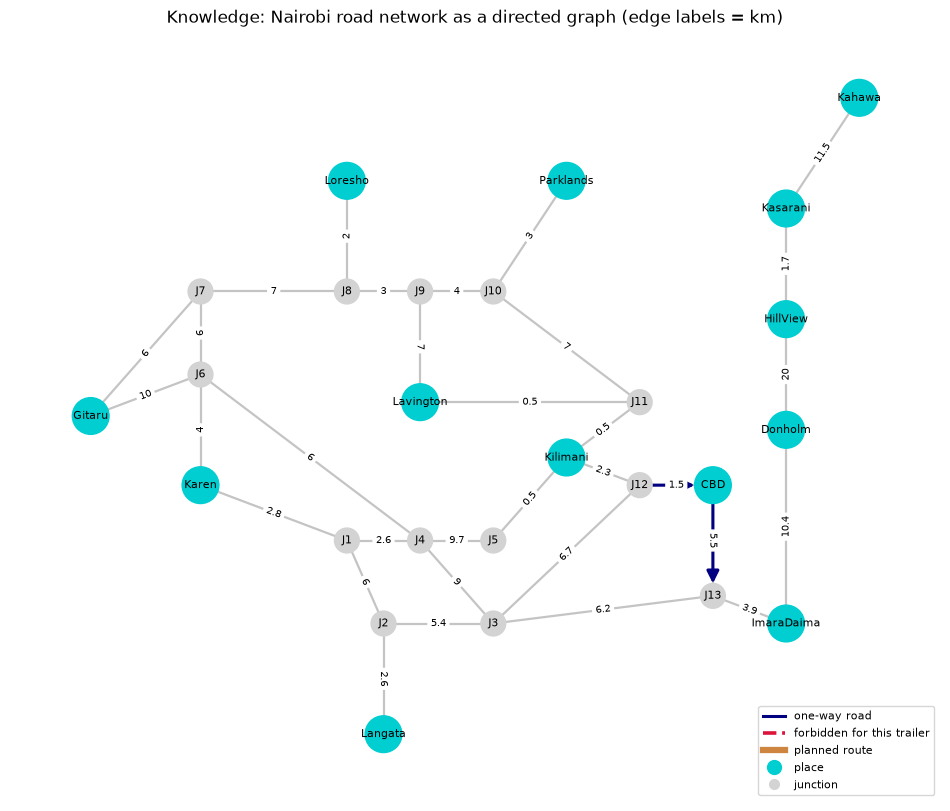

In [8]:
# ---------- 4.1 Road knowledge that Practical 3 does not contain ----------
# These segment attributes are scenario knowledge defined by the group (provenance = 'scenario').
# They are modelled on real Nairobi conditions but are NOT official KeNHA/KURA data.
ROAD_CLASS = {frozenset(pair): cls for cls, pairs in {
    "trunk":       [("J3", "J13"), ("J4", "J3"), ("J13", "ImaraDaima"), ("HillView", "Kasarani"), ("Kasarani", "Kahawa")],
    "primary":     [("Karen", "J1"), ("J1", "J2"), ("J1", "J4"), ("J4", "J5"), ("Karen", "J6"), ("J6", "J4"),
                    ("J6", "J7"), ("J7", "J8"), ("J8", "J9"), ("J9", "J10"), ("J10", "J11"), ("J3", "J12"),
                    ("J12", "CBD"), ("CBD", "J13"), ("ImaraDaima", "Donholm"), ("Donholm", "HillView")],
    "residential": [("J8", "Loresho"), ("J9", "Lavington"), ("Lavington", "J11"), ("J11", "Kilimani")],
}.items() for pair in pairs}                                         # anything unlisted is 'secondary'
ONE_WAY         = {("J12", "CBD"), ("CBD", "J13")}                   # CBD one-way system: only this direction exists
HGV_BANNED      = {frozenset(("J9", "Lavington")), frozenset(("Lavington", "J11"))}   # residential estate
CLEARANCE_M     = {frozenset(("J4", "J5")): 4.0}                     # low railway underpass
WEIGHT_LIMIT_T  = {frozenset(("J2", "Langata")): 18}                 # weak bridge
PEAK_RESTRICTED = {("J12", "CBD"), ("CBD", "J13")}                   # no HGVs in the CBD at peak hours
PEAK_HOURS      = [(6, 10), (16, 20)]                                # [start, end) in 24-hour time

def is_junction(name):
    return re.fullmatch(r"J\d+", name) is not None

def add_road_edge(G, u, v, km, road_class=None, source="Practical 3"):
    """TELL the graph one directed road u→v together with everything known about it."""
    key = frozenset((u, v))
    cls = road_class or ROAD_CLASS.get(key, "secondary")
    G.add_edge(u, v, km=float(km), road_class=cls, speed_limit=SPEED_LIMIT_BY_CLASS.get(cls, 50),
               hgv_banned=key in HGV_BANNED, clearance_m=CLEARANCE_M.get(key, math.inf),
               weight_limit_t=WEIGHT_LIMIT_T.get(key, math.inf), peak_restricted=(u, v) in PEAK_RESTRICTED,
               closed=None, source=source)

def build_road_graph():
    G = nx.DiGraph(name="Nairobi road network (directed)")
    for node, pos in P3_POSITIONS.items():
        G.add_node(node, pos=pos, kind="junction" if is_junction(node) else "place",
                   gps=GPS.get(node), gps_trusted=GPS.get(node) is not None)
    for u, v, km in P3_EDGES:
        for a, b in ((u, v), (v, u)):
            if (b, a) not in ONE_WAY:            # skip the forbidden direction of a one-way street
                add_road_edge(G, a, b, km)
    return G

ROADS = build_road_graph()
print(f"{ROADS.number_of_nodes()} nodes, {ROADS.number_of_edges()} directed roads "
      f"({len(P3_EDGES)} segments × 2 directions − {len(ONE_WAY)} one-way)")

def draw_network(G, route=(), blocked=(), title="Nairobi road network (directed)", ax=None):
    """Map in Practical 3's colours. Navy arrows = one-way, red dashes = forbidden for the trailer, peru = route."""
    pos = nx.get_node_attributes(G, "pos")
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 10))
    U = G.to_undirected()
    sizes = {n: 700 if d["kind"] == "place" else 320 for n, d in G.nodes(data=True)}
    nx.draw_networkx_edges(U, pos, ax=ax, edge_color="#c4c4c4", width=1.6)
    one_way = [(u, v) for u, v in G.edges if not G.has_edge(v, u)]
    nx.draw_networkx_edges(G, pos, edgelist=one_way, ax=ax, edge_color="navy", width=2.2, arrows=True,
                           arrowsize=18, node_size=[sizes[n] for n in G])
    if blocked:
        nx.draw_networkx_edges(U, pos, edgelist=list(blocked), ax=ax, edge_color="crimson", width=2.6, style="dashed")
    route_edges = list(zip(route, route[1:]))
    if route_edges:
        nx.draw_networkx_edges(G, pos, edgelist=route_edges, ax=ax, edge_color="peru", width=4.5, arrows=True,
                               arrowsize=20, node_size=[sizes[n] for n in G])
    colours = ["peru" if n in route else "darkturquoise" if d["kind"] == "place" else "lightgrey"
               for n, d in G.nodes(data=True)]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colours, node_size=[sizes[n] for n in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
    nx.draw_networkx_edge_labels(U, pos, ax=ax, font_size=7,
                                 edge_labels={(u, v): f"{d['km']:g}" for u, v, d in U.edges(data=True)})
    legend = [Line2D([], [], color="navy", lw=2.2, label="one-way road"),
              Line2D([], [], color="crimson", lw=2.6, ls="--", label="forbidden for this trailer"),
              Line2D([], [], color="peru", lw=4.5, label="planned route"),
              Line2D([], [], marker="o", color="w", markerfacecolor="darkturquoise", markersize=12, label="place"),
              Line2D([], [], marker="o", color="w", markerfacecolor="lightgrey", markersize=9, label="junction")]
    ax.legend(handles=legend, loc="lower right", fontsize=8)
    ax.set_title(title)
    ax.axis("off")
    return ax

draw_network(ROADS, title="Knowledge: Nairobi road network as a directed graph (edge labels = km)")
plt.show()

In [9]:
# ---------- 4.2 Rule base: Horn clauses  (premises are AND-ed; one conclusion per rule) ----------
ACTION_PRIORITY = {"EmergencyBrake": 100, "Stop": 90, "PullOver": 85, "Reroute": 80,
                   "ChangeLane": 70, "SlowDown": 60, "ProceedWithCaution": 50, "Proceed": 10}

GENERAL_RULES = [
    # name   premises                                              conclusion
    # --- traffic lights (extends the template's Red/Yellow/Green knowledge) ---
    ("L1",  [("Light", "Red")],                                    ("MustStop",)),
    ("L2",  [("Light", "FlashingRed")],                            ("MustStop",)),
    ("L3",  [("Light", "FlashingRed")],                            ("Advice", "ProceedOnlyWhenJunctionClear")),
    ("L4",  [("Light", "Off")],                                    ("MustStop",)),
    ("L5",  [("Light", "Off")],                                    ("Advice", "TreatJunctionAsAllWayStop")),
    ("L6",  [("Light", "Unknown")],                                ("MustStop",)),            # fail-safe
    ("L7",  [("Light", "Yellow"), ("CanStopSafely",)],             ("MustStop",)),
    ("L8",  [("Light", "Yellow"), ("CannotStopSafely",)],          ("Action", "ProceedWithCaution")),  # dilemma zone
    ("L9",  [("Light", "Green")],                                  ("Action", "Proceed")),
    ("L10", [("Light", "FlashingYellow")],                         ("Action", "SlowDown")),
    # --- how to stop a 40-tonne vehicle ---
    ("S1",  [("MustStop",)],                                       ("Action", "Stop")),
    ("S2",  [("MustStop",), ("CannotStopSafely",)],                ("Action", "EmergencyBrake")),
    # --- obstacles ---
    ("O1",  [("Obstacle", "Pedestrian")],                          ("Action", "EmergencyBrake")),
    ("O2",  [("Obstacle", "Cyclist")],                             ("Action", "SlowDown")),
    ("O3",  [("Obstacle", "Cyclist")],                             ("Advice", "KeepAtLeast1.5mClearance")),
    ("O4",  [("Obstacle", "Animal")],                              ("MustStop",)),
    ("O5",  [("Obstacle", "Animal")],                              ("Advice", "SoundHorn")),
    ("O6",  [("Obstacle", "StalledVehicle"), ("AdjacentLane", "Free")],    ("Action", "ChangeLane")),
    ("O7",  [("Obstacle", "StalledVehicle"), ("AdjacentLane", "Blocked")], ("MustStop",)),
    ("O8",  [("Obstacle", "Pothole")],                             ("Action", "SlowDown")),
    ("O9",  [("Obstacle", "Debris")],                              ("Action", "SlowDown")),
    ("O10", [("Obstacle", "RoadBlock")],                           ("Action", "Reroute")),
    # --- weather ---
    ("W1",  [("Weather", "Rain")],                                 ("Surface", "Wet")),
    ("W2",  [("Weather", "Storm")],                                ("Surface", "Wet")),
    ("W3",  [("Weather", "Storm")],                                ("LowVisibility",)),
    ("W4",  [("Weather", "Hail")],                                 ("Surface", "Wet")),
    ("W5",  [("Weather", "Hail")],                                 ("Action", "PullOver")),
    ("W6",  [("Weather", "Fog")],                                  ("LowVisibility",)),
    ("W7",  [("Surface", "Wet")],                                  ("Advice", "DoubleFollowingGap")),
    ("W8",  [("LowVisibility",)],                                  ("Action", "SlowDown")),
    ("W9",  [("LowVisibility",)],                                  ("Advice", "HeadlightsOn")),
    # --- sensor faults ---
    ("F1",  [("SensorConflict",)],                                 ("MustStop",)),
    ("F2",  [("SensorConflict",)],                                 ("Advice", "RequestRemoteOperator")),
    # --- legality of the trip ---
    ("T1",  [("Overweight",)],                                     ("TripNotPermitted",)),
    ("T2",  [("TooManyAxles",)],                                   ("TripNotPermitted",)),
]
print(f"{len(GENERAL_RULES)} general rules encoded")

35 general rules encoded


In [10]:
# ---------- 4.3 Inference engine ----------
def fmt(fact):
    """('Light', 'Red') -> 'Light(Red)';  ('MustStop',) -> 'MustStop'"""
    return fact[0] if len(fact) == 1 else f"{fact[0]}({', '.join(map(str, fact[1:]))})"

@dataclass(frozen=True)
class Rule:
    name: str
    premises: tuple
    conclusion: tuple
    source: str = "general knowledge"

    def __str__(self):
        return f"{' ∧ '.join(fmt(p) for p in self.premises)}  ⇒  {fmt(self.conclusion)}"

class KnowledgeBase:
    """Facts + Horn-clause rules + a directed road graph, with TELL / ASK / RETRACT."""

    def __init__(self, graph):
        self.graph = graph
        self.facts = {}           # permanent fact -> source (provenance)
        self.rules = []
        self.history = []         # the agent TELLs itself what it perceived and did

    # ----- TELL / RETRACT -----
    def tell(self, fact, source="told"):
        self.facts[tuple(fact)] = source

    def retract(self, fact):
        self.facts.pop(tuple(fact), None)

    def add_rule(self, name, premises, conclusion, source="general knowledge"):
        rule = Rule(name, tuple(map(tuple, premises)), tuple(conclusion), source)
        self.rules = [r for r in self.rules if r.name != name] + [rule]      # same name = redefinition
        return rule

    def vocabulary(self, predicate):
        """Constants the rules know for a predicate, e.g. vocabulary('Light') -> {'Red', 'Green', ...}."""
        return {f[1] for r in self.rules for f in (*r.premises, r.conclusion) if f[0] == predicate and len(f) > 1}

    # ----- ASK, data-driven: forward chaining -----
    def forward_chain(self, percepts=()):
        """Fire every rule whose premises all hold, until nothing new is derived. Returns (facts, rules fired)."""
        known, fired, changed = set(self.facts) | set(percepts), [], True
        while changed:
            changed = False
            for rule in self.rules:
                if rule.conclusion not in known and all(p in known for p in rule.premises):
                    known.add(rule.conclusion)
                    fired.append(rule)
                    changed = True
        return known, fired

    # ----- ASK, goal-driven: backward chaining (returns a proof tree, or None if unprovable) -----
    def prove(self, goal, percepts=(), _visiting=frozenset()):
        if goal in self.facts or goal in percepts:
            return {"fact": goal, "by": "given", "from": []}
        if goal in _visiting:                               # guard against circular rules
            return None
        for rule in self.rules:
            if rule.conclusion == goal:
                subproofs = [self.prove(p, percepts, _visiting | {goal}) for p in rule.premises]
                if all(subproofs):
                    return {"fact": goal, "by": rule, "from": subproofs}
        return None

def print_proof(proof, indent=1):
    by = "percept / fact" if proof["by"] == "given" else f"rule {proof['by'].name}: {proof['by']}"
    print("   " * indent + f"└ {fmt(proof['fact'])}   ⟸ {by}")
    for sub in proof["from"]:
        print_proof(sub, indent + 1)

KB = KnowledgeBase(ROADS)
for name, premises, conclusion in GENERAL_RULES:
    KB.add_rule(name, premises, conclusion)
for key, (value, source) in LEGAL.items():
    KB.tell(("Legal", key, value), source)

# ----- Procedural attachments: numbers -> symbols -----
def stopping_distance(speed_kmh, wet=False):
    """Reaction distance + braking distance:  d = v·t + v² / (2a)   [metres]."""
    v = speed_kmh / 3.6
    a = DOMAIN["decel_wet_ms2"] if wet else DOMAIN["decel_dry_ms2"]
    return v * DOMAIN["reaction_time_s"] + v ** 2 / (2 * a)

def perceive(kb, light=None, obstacle=None, speed_kmh=40, dist_m=None, weather="Clear", lane_free=True):
    """Turn raw sensor readings into symbolic percept facts (the TELL half of the agent loop)."""
    facts = {("Weather", weather)}
    lights = [light] if isinstance(light, str) else list(light or [])
    lights = [c if c in kb.vocabulary("Light") else "Unknown" for c in lights]     # unrecognised signal
    facts |= {("Light", c) for c in lights}
    if len(set(lights)) > 1:
        facts.add(("SensorConflict",))                    # e.g. the camera reports Red and Green at once
    if obstacle:
        facts.add(("Obstacle", obstacle if obstacle in kb.vocabulary("Obstacle") else "Unknown"))
        facts.add(("AdjacentLane", "Free" if lane_free else "Blocked"))
    wet = kb.prove(("Surface", "Wet"), {("Weather", weather)}) is not None          # ASK the KB
    stop_m = stopping_distance(speed_kmh, wet)
    room = math.inf if dist_m is None else dist_m         # distance unknown: assume room, i.e. prefer stopping
    facts.add(("CanStopSafely",) if stop_m <= room else ("CannotStopSafely",))
    return facts, stop_m, wet

@dataclass
class Decision:
    action: str
    advice: list
    percepts: set
    fired: list
    candidates: list
    stopping_m: float
    wet: bool

def decide(kb, **readings):
    """One cycle of the KB-agent: TELL percepts, forward-chain, ASK for the best action."""
    percepts, stop_m, wet = perceive(kb, **readings)
    known, fired = kb.forward_chain(percepts)
    candidates = sorted({f[1] for f in known if f[0] == "Action"}, key=lambda a: -ACTION_PRIORITY.get(a, 0))
    action = candidates[0] if candidates else "Proceed"   # closed-world default: nothing demands otherwise
    advice = sorted(f[1] for f in known if f[0] == "Advice")
    return Decision(action, advice, percepts, fired, candidates, stop_m, wet)

def explain(kb, d):
    print("  percepts :", ", ".join(sorted(fmt(p) for p in d.percepts)))
    print(f"  stopping distance at this speed: {d.stopping_m:.1f} m ({'wet' if d.wet else 'dry'} road)")
    for r in d.fired:
        print(f"  fired {r.name:<4} {r}")
    overridden = [a for a in d.candidates if a != d.action]
    print(f"  DECISION : {d.action}" + (f"   (higher priority than {', '.join(overridden)})" if overridden else ""))
    if d.advice:
        print("  advice   :", ", ".join(d.advice))
    proof = kb.prove(("Action", d.action), d.percepts)
    if proof:
        print("  proof (backward chaining):")
        print_proof(proof, 2)
    else:
        print("  proof: none needed. No rule demanded an action, so the closed-world default applies.")

# ----- Procedural attachments over the road graph -----
@dataclass
class Trailer:
    name: str = "KBA 001T"
    tare_t: float = 15.0          # prime mover + empty semi-trailer
    load_t: float = 28.0          # cargo
    height_m: float = 4.3
    axles: int = 6

    @property
    def gross_t(self):
        return self.tare_t + self.load_t

def is_peak(hour):
    return any(start <= hour < end for start, end in PEAK_HOURS)

def can_use(G, u, v, trailer, hour):
    """May this trailer drive road u→v at this hour? Returns (allowed, [reasons why not])."""
    if not G.has_edge(u, v):
        return False, [f"no road {u}→{v} (one-way street or not connected)"]
    d, why = G[u][v], []
    if d["closed"]:
        why.append(f"closed: {d['closed']}")
    if d["hgv_banned"]:
        why.append("heavy goods vehicles banned")
    if trailer.height_m > d["clearance_m"]:
        why.append(f"clearance {d['clearance_m']} m < trailer height {trailer.height_m} m")
    if trailer.gross_t > d["weight_limit_t"]:
        why.append(f"weight limit {d['weight_limit_t']} t < gross weight {trailer.gross_t:g} t")
    if d["peak_restricted"] and is_peak(hour):
        why.append(f"HGVs banned in peak hours {PEAK_HOURS}")
    return not why, why

def safe_speed(kb, u, v, weather):
    """Speed for road u→v = min(OSM speed limit, legal trailer cap), reduced for wet roads / low visibility."""
    speed = min(kb.graph[u][v]["speed_limit"], LEGAL["speed_cap_trailer_kmh"][0])
    if kb.prove(("Surface", "Wet"), {("Weather", weather)}):
        speed *= DOMAIN["wet_speed_factor"]
    if kb.prove(("LowVisibility",), {("Weather", weather)}):
        speed = min(speed, DOMAIN["low_visibility_cap_kmh"])
    return speed

def pretrip_check(kb, trailer):
    """Legal check before departure: returns (permitted, proof of TripNotPermitted or None)."""
    facts = set()
    if trailer.gross_t > LEGAL["max_gross_weight_t"][0]:
        facts.add(("Overweight",))
    if trailer.axles > LEGAL["max_axles"][0]:
        facts.add(("TooManyAxles",))
    proof = kb.prove(("TripNotPermitted",), facts)
    return proof is None, proof

# Quick sanity check of the engine on a template-style query
explain(KB, decide(KB, light="Red", speed_kmh=40, dist_m=60))

  percepts : CanStopSafely, Light(Red), Weather(Clear)
  stopping distance at this speed: 24.8 m (dry road)
  fired L1   Light(Red)  ⇒  MustStop
  fired S1   MustStop  ⇒  Action(Stop)
  DECISION : Stop
  proof (backward chaining):
      └ Action(Stop)   ⟸ rule S1: MustStop  ⇒  Action(Stop)
         └ MustStop   ⟸ rule L1: Light(Red)  ⇒  MustStop
            └ Light(Red)   ⟸ percept / fact


In [11]:
# ---------- 4.4 Distance measures and admissible heuristics ----------
def euclidean(p, q):
    return math.dist(p, q)

def manhattan(p, q):
    return abs(p[0] - q[0]) + abs(p[1] - q[1])

def chebyshev(p, q):
    return max(abs(p[0] - q[0]), abs(p[1] - q[1]))

METRICS = {"euclidean": euclidean, "manhattan": manhattan, "chebyshev": chebyshev}   # + haversine (Step 2) for GPS

def make_heuristic(G, goal, metric="euclidean", scaled=True):
    """h(n) = k · metric(pos(n), pos(goal)).
    Practical 3's positions are a schematic map (not in km), so the raw metric can overestimate.
    Scaling by k = min over all roads of (km / metric length) guarantees h(u) ≤ cost(u, v) + h(v) on every
    road (consistent, hence admissible), by the triangle inequality of the metric."""
    pos, dist = nx.get_node_attributes(G, "pos"), METRICS[metric]
    k = (min(d["km"] / dist(pos[u], pos[v]) for u, v, d in G.edges(data=True) if dist(pos[u], pos[v]) > 0)
         if scaled else 1.0)
    h = lambda n: k * dist(pos[n], pos[goal])
    h.k, h.label = k, metric + ("" if scaled else " (unscaled)")
    return h

goal = "Parklands"
h_true = nx.single_source_dijkstra_path_length(ROADS.reverse(copy=False), goal, weight="km")  # exact cost-to-go
hs = {m: make_heuristic(ROADS, goal, m) for m in METRICS}
pos = nx.get_node_attributes(ROADS, "pos")
table = pd.DataFrame([{
    "node": n,
    **{f"{m} (raw)": round(METRICS[m](pos[n], pos[goal]), 2) for m in METRICS},
    **{f"h {m} (scaled)": round(hs[m](n), 2) for m in METRICS},
    "true road km h*(n)": round(h_true[n], 1),
    "haversine km (GPS)": round(haversine(GPS[n], GPS[goal]), 1) if GPS.get(n) else None,
} for n in ["Karen", "J6", "J7", "J9", "J4", "J5", "Kilimani", "Lavington", "J10", "CBD"]]).set_index("node")
print(f"Distance measures to the goal '{goal}'. Scale factors k: "
      + ", ".join(f"{m} = {h.k:.3f}" for m, h in hs.items()))
display(table)
print("Note: k is small because 0.5 km roads such as J5–Kilimani and Lavington–J11 are drawn ~6 units long in\n"
      "Practical 3's schematic map. Scaling keeps A* optimal but makes h weak; Step 9 shows what happens without it.")

Distance measures to the goal 'Parklands'. Scale factors k: euclidean = 0.079, manhattan = 0.062, chebyshev = 0.083


,euclidean (raw),manhattan (raw),chebyshev (raw),h euclidean (scaled),h manhattan (scaled),h chebyshev (scaled),true road km h*(n),haversine km (GPS)
node,,,,,,,,
Karen,24.17,32,22,1.91,2.00,1.83,26.1,13.8
J6,17.20,24,14,1.36,1.50,1.17,23.0,NaN
J7,12.81,18,10,1.01,1.12,0.83,17.0,NaN
J9,8.94,12,8,0.71,0.75,0.67,7.0,NaN
J4,26.31,30,26,2.08,1.88,2.17,20.7,NaN
J5,26.08,28,26,2.06,1.75,2.17,11.0,NaN
Kilimani,20.00,20,20,1.58,1.25,1.67,10.5,4.9
Lavington,16.49,20,16,1.30,1.25,1.33,10.5,4.0
J10,8.25,10,8,0.65,0.62,0.67,3.0,NaN


Note: k is small because 0.5 km roads such as J5–Kilimani and Lavington–J11 are drawn ~6 units long in
Practical 3's schematic map. Scaling keeps A* optimal but makes h weak; Step 9 shows what happens without it.


### The initial knowledge base

The function below displays the knowledge base. It is reused in Step 5 to show what has been added since.

In [12]:
def restriction_text(G, u, v):
    d, parts = G[u][v], []
    if not G.has_edge(v, u):              parts.append("one-way")
    if d["hgv_banned"]:                   parts.append("HGV ban")
    if d["clearance_m"] < math.inf:       parts.append(f"clearance {d['clearance_m']} m")
    if d["weight_limit_t"] < math.inf:    parts.append(f"weight limit {d['weight_limit_t']} t")
    if d["peak_restricted"]:              parts.append("no HGVs at peak hours")
    if d["closed"]:                       parts.append(f"CLOSED: {d['closed']}")
    return ", ".join(parts)

def show_kb(kb, only_new=False):
    G = kb.graph
    print(f"--- Knowledge base: {len(kb.rules)} rules · {len(kb.facts)} facts · "
          f"{G.number_of_nodes()} nodes · {G.number_of_edges()} directed roads ---")
    rules = [r for r in kb.rules if not only_new or r.source != "general knowledge"]
    if rules:
        display(pd.DataFrame([{"rule": r.name, "IF": " ∧ ".join(map(fmt, r.premises)), "THEN": fmt(r.conclusion),
                               "source": r.source} for r in rules]).set_index("rule"))
    facts = [(f, s) for f, s in kb.facts.items() if not only_new or f[0] != "Legal"]
    if facts:
        display(pd.DataFrame([{"fact": fmt(f), "source": s} for f, s in facts]))
    special = [{"road": f"{u}→{v}", "km": d["km"], "class": d["road_class"], "limit km/h": d["speed_limit"],
                "restriction": restriction_text(G, u, v), "source": d["source"]}
               for u, v, d in G.edges(data=True) if restriction_text(G, u, v) or d["source"] != "Practical 3"]
    display(pd.DataFrame(special).set_index("road"))

show_kb(KB)

--- Knowledge base: 35 rules · 4 facts · 26 nodes · 62 directed roads ---


,IF,THEN,source
rule,,,
L1,Light(Red),MustStop,general knowledge
L2,Light(FlashingRed),MustStop,general knowledge
L3,Light(FlashingRed),Advice(ProceedOnlyWhenJunctionClear),general knowledge
L4,Light(Off),MustStop,general knowledge
L5,Light(Off),Advice(TreatJunctionAsAllWayStop),general knowledge
L6,Light(Unknown),MustStop,general knowledge
L7,Light(Yellow) ∧ CanStopSafely,MustStop,general knowledge
L8,Light(Yellow) ∧ CannotStopSafely,Action(ProceedWithCaution),general knowledge
L9,Light(Green),Action(Proceed),general knowledge


,fact,source
0,"Legal(speed_cap_trailer_kmh, 65)",Kenya Traffic (Speed Limits) Rules: vehicle drawing one trailer
1,"Legal(speed_cap_commercial_kmh, 80)","Kenya Traffic Act Cap. 403: commercial vehicles, any road"
2,"Legal(max_gross_weight_t, 56)","EAC Vehicle Load Control Act, 2016"
3,"Legal(max_axles, 7)","EAC Vehicle Load Control Act, 2016"


,km,class,limit km/h,restriction,source
road,,,,,
J4→J5,9.7,primary,50,clearance 4.0 m,Practical 3
J5→J4,9.7,primary,50,clearance 4.0 m,Practical 3
J2→Langata,2.6,secondary,50,weight limit 18 t,Practical 3
Langata→J2,2.6,secondary,50,weight limit 18 t,Practical 3
J9→Lavington,7.0,residential,50,HGV ban,Practical 3
Lavington→J9,7.0,residential,50,HGV ban,Practical 3
Lavington→J11,0.5,residential,50,HGV ban,Practical 3
J11→Lavington,0.5,residential,50,HGV ban,Practical 3
J12→CBD,1.5,primary,50,"one-way, no HGVs at peak hours",Practical 3


## Step 5: Add New Facts to the Knowledge Base `[4 marks]`

A knowledge-based agent must be able to **learn without being reprogrammed**. New knowledge enters this KB in three ways:
1. **Directly from the knowledge engineer**, with no user input: new rules (a synonym, a new hazard), a new road closure.
2. **From an API at run time**: a new place (Westlands) is geocoded live by Nominatim and connected to the road graph.
3. **Interactively from the user**: a new traffic-light signal and the action for it. The input is **validated** so the KB stays consistent: only known actions are accepted, and misspellings are corrected or rejected.

In [13]:
def add_new_rule(kb, name, premises, conclusion, source="knowledge engineer"):
    if conclusion[0] == "Action" and conclusion[1] not in ACTION_PRIORITY:
        raise ValueError(f"Unknown action '{conclusion[1]}': choose one of {list(ACTION_PRIORITY)}")
    rule = kb.add_rule(name, premises, conclusion, source)
    print(f"Added rule {name}: {rule}   [{source}]")

def add_new_fact(kb, fact, source="knowledge engineer"):
    kb.tell(fact, source)
    print(f"Added fact: {fmt(fact)}   [{source}]")

def close_road(kb, u, v, reason, both_ways=True, verbose=True):
    for a, b in ((u, v), (v, u)) if both_ways else ((u, v),):
        if kb.graph.has_edge(a, b):
            kb.graph[a][b]["closed"] = reason
            kb.tell(("Closed", a, b), reason)
            if verbose:
                print(f"Added fact: Closed({a}, {b})   [{reason}]")

def reopen_road(kb, u, v, both_ways=True):
    for a, b in ((u, v), (v, u)) if both_ways else ((u, v),):
        if kb.graph.has_edge(a, b) and kb.graph[a][b]["closed"]:
            kb.graph[a][b]["closed"] = None
            kb.retract(("Closed", a, b))
            print(f"Retracted fact: Closed({a}, {b})")

def add_place(kb, name, pos, roads, query=None):
    """New place: geocode it live (Source 2) and connect it with two-way roads [(neighbour, km), ...]."""
    gps, radius, source = geocode(name, query or f"{name}, Nairobi")
    GPS[name], GPS_RADIUS[name], GPS_SOURCE[name] = gps, radius, source
    kb.graph.add_node(name, pos=pos, kind="place", gps=gps, gps_trusted=gps is not None)
    for neighbour, km in roads:
        add_road_edge(kb.graph, name, neighbour, km, source="knowledge engineer")
        add_road_edge(kb.graph, neighbour, name, km, source="knowledge engineer")
    print(f"Added place: {name} at GPS {tuple(round(c, 4) for c in gps) if gps else '?'} [{source}], "
          f"roads to {', '.join(n for n, _ in roads)}")

# (1) The knowledge engineer adds facts and rules directly (no user input)
add_new_rule(KB, "L11", [("Light", "Amber")], ("Light", "Yellow"))             # local word for yellow
add_new_rule(KB, "O11", [("Obstacle", "SchoolZone")], ("Action", "SlowDown"))
add_new_rule(KB, "O12", [("Obstacle", "SchoolZone")], ("Advice", "MaxSpeed30"))
close_road(KB, "J4", "J3", reason="roadworks (scenario)")

# (2) New knowledge from an API at run time
add_place(KB, "Westlands", pos=(11, 16), roads=[("J10", 2.5), ("Parklands", 3.5)])

# (3) The user adds a new signal interactively; the input is validated against the vocabulary
def add_light_rule_from_user(kb):
    colour = re.sub(r"\W", "", ask_user("New traffic-light signal", "White")).capitalize()
    answer = ask_user(f"What must the trailer do on '{colour}'? One of {list(ACTION_PRIORITY)}", "Stop")
    by_lower = {a.lower(): a for a in ACTION_PRIORITY}
    match = difflib.get_close_matches(answer.lower().replace(" ", ""), by_lower, n=1, cutoff=0.6)
    if not colour or not match:
        print(f"Rejected: '{answer}' is not a known action, so the KB is left unchanged.")
        return
    action = by_lower[match[0]]
    # 'Stop' is encoded as MustStop, so the emergency-brake rule S2 also applies to the new signal
    conclusion = ("MustStop",) if action == "Stop" else ("Action", action)
    add_new_rule(kb, f"U_{colour}", [("Light", colour)], conclusion, source="user (interactive)")

add_light_rule_from_user(KB)

# View the knowledge that was added
show_kb(KB, only_new=True)

Added rule L11: Light(Amber)  ⇒  Light(Yellow)   [knowledge engineer]
Added rule O11: Obstacle(SchoolZone)  ⇒  Action(SlowDown)   [knowledge engineer]
Added rule O12: Obstacle(SchoolZone)  ⇒  Advice(MaxSpeed30)   [knowledge engineer]
Added fact: Closed(J4, J3)   [roadworks (scenario)]
Added fact: Closed(J3, J4)   [roadworks (scenario)]


Added place: Westlands at GPS (-1.2465, 36.7861) [Nominatim API], roads to J10, Parklands
New traffic-light signal: White   (default; set INTERACTIVE = True to type your own)
What must the trailer do on 'White'? One of ['EmergencyBrake', 'Stop', 'PullOver', 'Reroute', 'ChangeLane', 'SlowDown', 'ProceedWithCaution', 'Proceed']: Stop   (default; set INTERACTIVE = True to type your own)
Added rule U_White: Light(White)  ⇒  MustStop   [user (interactive)]
--- Knowledge base: 39 rules · 6 facts · 27 nodes · 66 directed roads ---


,IF,THEN,source
rule,,,
L11,Light(Amber),Light(Yellow),knowledge engineer
O11,Obstacle(SchoolZone),Action(SlowDown),knowledge engineer
O12,Obstacle(SchoolZone),Advice(MaxSpeed30),knowledge engineer
U_White,Light(White),MustStop,user (interactive)


,fact,source
0,"Closed(J4, J3)",roadworks (scenario)
1,"Closed(J3, J4)",roadworks (scenario)


,km,class,limit km/h,restriction,source
road,,,,,
J4→J5,9.7,primary,50,clearance 4.0 m,Practical 3
J4→J3,9.0,trunk,50,CLOSED: roadworks (scenario),Practical 3
J5→J4,9.7,primary,50,clearance 4.0 m,Practical 3
J2→Langata,2.6,secondary,50,weight limit 18 t,Practical 3
Langata→J2,2.6,secondary,50,weight limit 18 t,Practical 3
J3→J4,9.0,trunk,50,CLOSED: roadworks (scenario),Practical 3
J9→Lavington,7.0,residential,50,HGV ban,Practical 3
J10→Westlands,2.5,secondary,50,,knowledge engineer
Parklands→Westlands,3.5,secondary,50,,knowledge engineer


## Steps 6 & 7: Encode the Specific Problem Instance (Facts) & Pose Queries and Get Answers `[3 marks]`

**Step 6** describes *this* trip: the trailer's dimensions and load, the depot, the customer, the departure time and the live weather.

**Step 7** asks the KB two kinds of question:
- **"Which legal route is best?"** Several strategies grow a **search tree** over the directed graph: BFS and UCS from Practical 3, plus Greedy best-first and A* with the distance measures from Step 4.4. The successor function only offers roads the trailer may legally use (`can_use`), and every rejected road is recorded with its reason.
- **"What should I do now?"** The trailer then *drives* the route. At each node it senses the environment and runs the TELL → forward-chain → ASK cycle. If it meets a road block, it TELLs the KB the road is closed and **re-plans**.

In [14]:
# ---------- Step 6: the specific problem instance ----------
def resolve_place(G, text):
    """Case- and space-insensitive lookup of a node name, with a 'did you mean' suggestion."""
    norm = lambda s: re.sub(r"[\s_\-]", "", s).lower()
    names = {norm(n): n for n in G}
    if norm(text) in names:
        return names[norm(text)]
    guess = difflib.get_close_matches(norm(text), names, n=1, cutoff=0.6)
    raise ValueError(f"Unknown place '{text}'." + (f" Did you mean '{names[guess[0]]}'?" if guess else ""))

TRAILER     = Trailer(name="KBA 001T", tare_t=15.0, load_t=float(ask_user("Cargo load (tonnes)", 28)), height_m=4.3, axles=6)
ORIGIN      = resolve_place(KB.graph, ask_user("Depot (origin)", "Karen"))
DESTINATION = resolve_place(KB.graph, ask_user("Delivery point (destination)", "Parklands"))
DEPART_HOUR = int(ask_user("Departure hour (0-23)", 7))
WEATHER     = WEATHER_NOW                       # live percept from Open-Meteo (Step 2)

for fact in [("At", ORIGIN), ("Goal", DESTINATION), ("GrossWeight", TRAILER.gross_t), ("Height", TRAILER.height_m),
             ("Axles", TRAILER.axles), ("Hour", DEPART_HOUR)]:
    add_new_fact(KB, fact, source="trip instance")
print(f"Percept: Weather({WEATHER})  [{WEATHER_SOURCE}]. Weather is sensed again at every step, not stored permanently.")

permitted, proof = pretrip_check(KB, TRAILER)
print(f"\nPre-trip legal check: gross weight {TRAILER.gross_t:g} t (max {LEGAL['max_gross_weight_t'][0]} t), "
      f"{TRAILER.axles} axles (max {LEGAL['max_axles'][0]}) → {'PERMITTED' if permitted else 'NOT PERMITTED'}")
if proof:
    print_proof(proof)

Cargo load (tonnes): 28   (default; set INTERACTIVE = True to type your own)
Depot (origin): Karen   (default; set INTERACTIVE = True to type your own)
Delivery point (destination): Parklands   (default; set INTERACTIVE = True to type your own)
Departure hour (0-23): 7   (default; set INTERACTIVE = True to type your own)
Added fact: At(Karen)   [trip instance]
Added fact: Goal(Parklands)   [trip instance]
Added fact: GrossWeight(43.0)   [trip instance]
Added fact: Height(4.3)   [trip instance]
Added fact: Axles(6)   [trip instance]
Added fact: Hour(7)   [trip instance]
Percept: Weather(Clear)  [Open-Meteo API]. Weather is sensed again at every step, not stored permanently.

Pre-trip legal check: gross weight 43 t (max 56 t), 6 axles (max 7) → PERMITTED


In [15]:
# ---------- Step 7a: search-tree strategies over the directed graph ----------
@dataclass
class SearchResult:
    algorithm: str
    path: list
    cost: float
    expanded: list                                   # node ids, in expansion order
    nodes: dict                                      # id -> {state, parent, g, h, depth}: the search tree
    goal_id: int = None
    pruned: dict = field(default_factory=dict)       # (u, v) -> reasons the trailer may not use that road

def search(kb, start, goal, trailer, hour, strategy="astar", h=None):
    """Graph search that records the whole search tree.
    bfs   : FIFO queue, goal test when a node is generated (as in Practical 3) → fewest road segments
    ucs   : priority g(n)           ┐
    greedy: priority h(n)           ├ goal test when a node is expanded
    astar : priority g(n) + h(n)    ┘"""
    G, h = kb.graph, h or (lambda n: 0.0)
    nodes, expanded, pruned, tie = {}, [], {}, itertools.count()

    def new_node(state, parent, g):
        i = len(nodes)
        nodes[i] = {"state": state, "parent": parent, "g": g, "h": h(state),
                    "depth": 0 if parent is None else nodes[parent]["depth"] + 1}
        return i

    def successors(state):                           # ASK the KB which roads are legal for this trailer
        for nxt in G.successors(state):
            ok, why = can_use(G, state, nxt, trailer, hour)
            if ok:
                yield nxt, G[state][nxt]["km"]
            else:
                pruned[(state, nxt)] = why

    def result(goal_id):
        path, i = [], goal_id
        while i is not None:
            path.append(nodes[i]["state"])
            i = nodes[i]["parent"]
        return SearchResult(strategy, path[::-1], nodes[goal_id]["g"], expanded, nodes, goal_id, pruned)

    root = new_node(start, None, 0.0)
    if strategy == "bfs":
        if start == goal:
            return result(root)
        frontier, reached = [root], {start}
        while frontier:
            i = frontier.pop(0)
            expanded.append(i)
            for nxt, km in successors(nodes[i]["state"]):
                if nxt not in reached:
                    reached.add(nxt)
                    child = new_node(nxt, i, nodes[i]["g"] + km)
                    if nxt == goal:
                        return result(child)
                    frontier.append(child)
    else:
        f = {"ucs": lambda n: n["g"], "greedy": lambda n: n["h"], "astar": lambda n: n["g"] + n["h"]}[strategy]
        frontier, best_g = [(f(nodes[root]), next(tie), root)], {start: 0.0}
        while frontier:
            _, _, i = heapq.heappop(frontier)
            n = nodes[i]
            if n["g"] > best_g[n["state"]]:
                continue                                  # stale entry: a cheaper path was found later
            expanded.append(i)
            if n["state"] == goal:
                return result(i)
            for nxt, km in successors(n["state"]):
                g = n["g"] + km
                if g < best_g.get(nxt, math.inf):
                    best_g[nxt] = g
                    child = new_node(nxt, i, g)
                    heapq.heappush(frontier, (f(nodes[child]), next(tie), child))
    return SearchResult(strategy, [], math.inf, expanded, nodes, None, pruned)      # no legal route

def permitted_graph(kb, trailer, hour):
    """The sub-graph of roads this trailer may legally use (for verification with networkx)."""
    P = nx.DiGraph()
    P.add_nodes_from(kb.graph.nodes(data=True))
    P.add_edges_from((u, v, d) for u, v, d in kb.graph.edges(data=True) if can_use(kb.graph, u, v, trailer, hour)[0])
    return P

def true_cost(P, a, b):
    try:
        return nx.dijkstra_path_length(P, a, b, weight="km")
    except nx.NetworkXNoPath:
        return math.inf

def draw_search_tree(res, title):
    nodes, children = res.nodes, defaultdict(list)
    for i, n in nodes.items():
        if n["parent"] is not None:
            children[n["parent"]].append(i)
    on_path, i = set(), res.goal_id
    while i is not None:
        on_path.add(i)
        i = nodes[i]["parent"]
    pos, leaves = {}, [0]
    def place(i):                                        # tidy layout: leaves left→right, parents centred
        for c in children[i]:
            place(c)
        if children[i]:
            x = sum(pos[c][0] for c in children[i]) / len(children[i])
        else:
            x, leaves[0] = leaves[0], leaves[0] + 1
        pos[i] = (x, -nodes[i]["depth"])
    place(0)
    rank = {i: r + 1 for r, i in enumerate(res.expanded)}
    T = nx.DiGraph([(n["parent"], i) for i, n in nodes.items() if n["parent"] is not None])
    T.add_node(0)
    labels = {i: f"{nodes[i]['state']}" + (f" #{rank[i]}" if i in rank else "") +
                 f"\ng={nodes[i]['g']:.1f}" + (f"\nh={nodes[i]['h']:.1f}" if nodes[i]["h"] else "") for i in T}
    colours = ["peru" if i in on_path else "darkturquoise" if i in rank else "lightgrey" for i in T]
    fig, ax = plt.subplots(figsize=(max(12, 0.85 * leaves[0]), 1.5 * (max(n["depth"] for n in nodes.values()) + 1) + 1))
    nx.draw(T, pos, ax=ax, labels=labels, node_color=colours, node_size=1500, font_size=6.5, arrows=False,
            edge_color="#999999")
    ax.set_title(f"{title}\nperu = solution path · turquoise = expanded (#order) · grey = generated, never expanded")
    plt.show()

# ---- Query: best legal route from ORIGIN to DESTINATION ----
G = KB.graph
runs = {
    "BFS (Practical 3)":                      search(KB, ORIGIN, DESTINATION, TRAILER, DEPART_HOUR, "bfs"),
    "UCS (Practical 3)":                      search(KB, ORIGIN, DESTINATION, TRAILER, DEPART_HOUR, "ucs"),
    "Greedy best-first · euclidean":          search(KB, ORIGIN, DESTINATION, TRAILER, DEPART_HOUR, "greedy",
                                                     make_heuristic(G, DESTINATION, "euclidean")),
    "A* · scaled euclidean":                  search(KB, ORIGIN, DESTINATION, TRAILER, DEPART_HOUR, "astar",
                                                     make_heuristic(G, DESTINATION, "euclidean")),
    "A* · scaled manhattan":                  search(KB, ORIGIN, DESTINATION, TRAILER, DEPART_HOUR, "astar",
                                                     make_heuristic(G, DESTINATION, "manhattan")),
    "A* · scaled chebyshev":                  search(KB, ORIGIN, DESTINATION, TRAILER, DEPART_HOUR, "astar",
                                                     make_heuristic(G, DESTINATION, "chebyshev")),
    "A* · unscaled euclidean (inadmissible)": search(KB, ORIGIN, DESTINATION, TRAILER, DEPART_HOUR, "astar",
                                                     make_heuristic(G, DESTINATION, "euclidean", scaled=False)),
}
optimum = true_cost(permitted_graph(KB, TRAILER, DEPART_HOUR), ORIGIN, DESTINATION)
display(pd.DataFrame([{"strategy": name, "nodes expanded": len(r.expanded), "nodes generated": len(r.nodes),
                       "route": " → ".join(r.path) or "no legal route", "km": round(r.cost, 1),
                       "optimal?": math.isclose(r.cost, optimum)} for name, r in runs.items()]).set_index("strategy"))
print(f"Optimal legal distance (networkx Dijkstra on the permitted sub-graph): {optimum:.1f} km")

,nodes expanded,nodes generated,route,km,optimal?
strategy,,,,,
BFS (Practical 3),16,20,Karen → J6 → J7 → J8 → J9 → J10 → Parklands,27.0,True
UCS (Practical 3),20,21,Karen → J6 → J7 → J8 → J9 → J10 → Parklands,27.0,True
Greedy best-first · euclidean,8,13,Karen → J6 → J7 → J8 → J9 → J10 → Parklands,27.0,True
A* · scaled euclidean,20,22,Karen → J6 → J7 → J8 → J9 → J10 → Parklands,27.0,True
A* · scaled manhattan,20,21,Karen → J6 → J7 → J8 → J9 → J10 → Parklands,27.0,True
A* · scaled chebyshev,19,22,Karen → J6 → J7 → J8 → J9 → J10 → Parklands,27.0,True
A* · unscaled euclidean (inadmissible),10,15,Karen → J6 → J7 → J8 → J9 → J10 → Parklands,27.0,True


Optimal legal distance (networkx Dijkstra on the permitted sub-graph): 27.0 km


Planned route (27.0 km, ≈32 min; weather: Clear):
  Karen → J6 → J7 → J8 → J9 → J10 → Parklands

The shortest route if restrictions are ignored would be Karen → J1 → J4 → J5 → Kilimani → J11 → J10 → Parklands (26.1 km), but the KB rejects it:
  ✗ J4→J5: clearance 4.0 m < trailer height 4.3 m

Roads pruned from the search tree (reasons recorded by the KB):
  J11→Lavington: heavy goods vehicles banned
  J12→CBD: HGVs banned in peak hours [(6, 10), (16, 20)]
  J2→Langata: weight limit 18 t < gross weight 43 t
  J3→J4: closed: roadworks (scenario)
  J4→J3: closed: roadworks (scenario)
  J4→J5: clearance 4.0 m < trailer height 4.3 m
  J5→J4: clearance 4.0 m < trailer height 4.3 m
  J9→Lavington: heavy goods vehicles banned


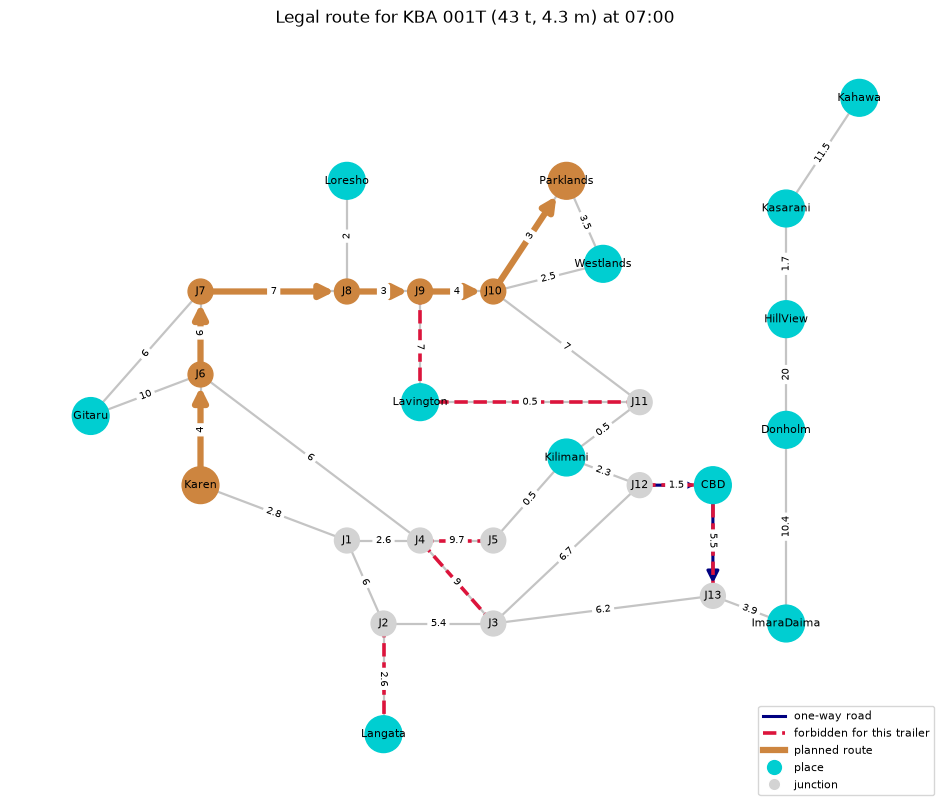

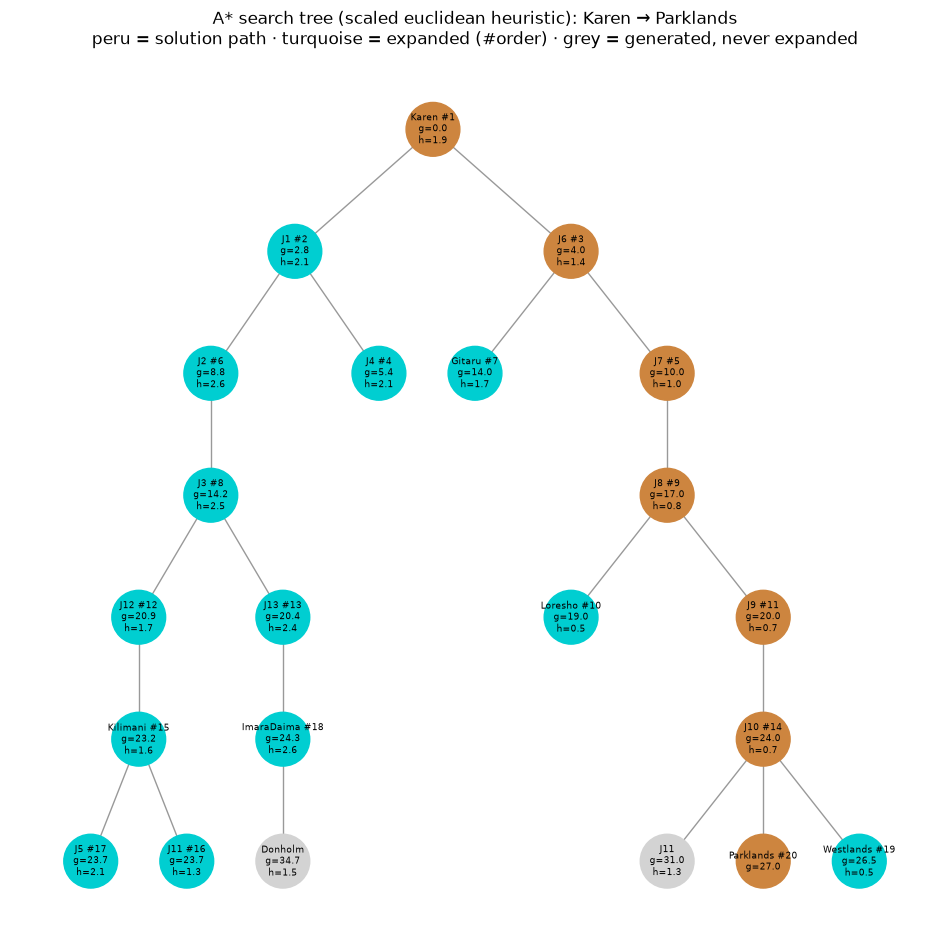

In [16]:
# ---------- Step 7b: the chosen route, explained ----------
best = runs["A* · scaled euclidean"]
ROUTE = best.path
minutes = sum(G[u][v]["km"] / safe_speed(KB, u, v, WEATHER) * 60 for u, v in zip(ROUTE, ROUTE[1:]))
print(f"Planned route ({best.cost:.1f} km, ≈{minutes:.0f} min; weather: {WEATHER}):\n  " + " → ".join(ROUTE))

unrestricted = nx.shortest_path(G, ORIGIN, DESTINATION, weight="km")
if unrestricted != ROUTE:
    print(f"\nThe shortest route if restrictions are ignored would be {' → '.join(unrestricted)} "
          f"({nx.path_weight(G, unrestricted, 'km'):.1f} km), but the KB rejects it:")
    for u, v in zip(unrestricted, unrestricted[1:]):
        ok, why = can_use(G, u, v, TRAILER, DEPART_HOUR)
        if not ok:
            print(f"  ✗ {u}→{v}: {'; '.join(why)}")

print("\nRoads pruned from the search tree (reasons recorded by the KB):")
for (u, v), why in sorted(best.pruned.items()):
    print(f"  {u}→{v}: {'; '.join(why)}")

blocked = {tuple(sorted((u, v))) for u, v in G.edges if not can_use(G, u, v, TRAILER, DEPART_HOUR)[0]}
draw_network(G, route=ROUTE, blocked=blocked,
             title=f"Legal route for {TRAILER.name} ({TRAILER.gross_t:g} t, {TRAILER.height_m} m) at {DEPART_HOUR:02d}:00")
plt.show()
draw_search_tree(best, f"A* search tree (scaled euclidean heuristic): {ORIGIN} → {DESTINATION}")

In [17]:
# ---------- Step 7c: autonomous drive. At every node: sense → TELL → forward-chain → ASK → act ----------
SCRIPTED_PERCEPTS = {     # test scenario: what the sensors report on arrival at these nodes (each happens once)
    "J6": dict(light="Yellow", speed_kmh=48, dist_m=22),                # too close to stop → dilemma zone
    "J7": dict(light="Red", speed_kmh=45, dist_m=70),                   # plenty of room → normal stop
    "J8": dict(light="Green", obstacle="Pedestrian", speed_kmh=30, dist_m=25),   # pedestrian beats green
    "J9": dict(obstacle="RoadBlock", speed_kmh=25),                     # accident ahead → re-plan
}

def sense(node, rng, approach_kmh, events):
    """Simulated sensors: a scripted event if one is pending here, otherwise random but plausible readings."""
    if node in events:
        return events.pop(node)
    reading = {"speed_kmh": round(approach_kmh)}
    if is_junction(node):
        reading["light"] = rng.choice(["Green", "Green", "Green", "Red", "Yellow"])
    if rng.random() < 0.15:
        reading["obstacle"] = rng.choice(["Pothole", "Cyclist", "Debris", "Animal"])
    if "light" in reading or "obstacle" in reading:
        reading["dist_m"] = rng.choice([20, 40, 60, 90])        # distance to the stop line / hazard
    return reading

def drive(kb, trailer, origin, goal, hour, weather, seed=7):
    rng, events, G = random.Random(seed), dict(SCRIPTED_PERCEPTS), kb.graph
    route = search(kb, origin, goal, trailer, hour, "astar", make_heuristic(G, goal)).path
    if not route:
        print("No legal route: trip cancelled.")
        return pd.DataFrame()
    print(f"Departing {origin} for {goal}: {' → '.join(route)}")
    log, km_done, minutes, speed = [], 0.0, 0.0, 0.0
    while route[0] != goal:
        at, nxt = route[0], route[1]
        scripted = at in events
        reading = sense(at, rng, speed, events)
        d = decide(kb, weather=weather, **reading)
        kb.history.append((at, frozenset(d.percepts), d.action))           # TELL: what was perceived and done
        notes = []
        if scripted:                                                       # narrate the scenario events in full
            print(f"\n▶ {at}: sensors report {reading}")
            explain(kb, d)
        if "Reroute" in d.candidates:
            close_road(kb, at, nxt, "road block reported by sensors", both_ways=False, verbose=False)
            new = search(kb, at, goal, trailer, hour, "astar", make_heuristic(G, goal))
            if not new.path:
                print(f"  No legal route from {at} after the road block: waiting for the road to reopen.")
                break
            notes.append(f"TELL Closed({at}, {nxt}); re-planned {new.cost:.1f} km")
            print(f"  → {notes[-1]}: {' → '.join(new.path)}")
            route, nxt = new.path, new.path[1]
        if d.action in ("Stop", "EmergencyBrake", "PullOver"):
            minutes += 1.0
            notes.append("held until clear, then continued")
        note = "; ".join(notes)
        speed = safe_speed(kb, at, nxt, weather) * (0.6 if d.action == "SlowDown" else 1.0)
        km = G[at][nxt]["km"]
        km_done, minutes = km_done + km, minutes + km / speed * 60
        log.append({"at": at, "percepts": ", ".join(sorted(fmt(p) for p in d.percepts
                                                           if p[0] not in ("CanStopSafely", "Weather"))),
                    "action": d.action, "advice": ", ".join(d.advice), "next road": f"{at}→{nxt}",
                    "km/h": round(speed), "km so far": round(km_done, 1), "note": note})
        route = route[1:]
    else:
        log.append({"at": goal, "percepts": "", "action": "Arrived", "advice": "", "next road": "", "km/h": "",
                    "km so far": round(km_done, 1), "note": f"delivered after ≈{minutes:.0f} min"})
    return pd.DataFrame(log)

trip_log = drive(KB, TRAILER, ORIGIN, DESTINATION, DEPART_HOUR, WEATHER)
display(trip_log)
print(f"Decision cycles recorded in the KB history: {len(KB.history)}")

Departing Karen for Parklands: Karen → J6 → J7 → J8 → J9 → J10 → Parklands

▶ J6: sensors report {'light': 'Yellow', 'speed_kmh': 48, 'dist_m': 22}
  percepts : CannotStopSafely, Light(Yellow), Weather(Clear)
  stopping distance at this speed: 33.1 m (dry road)
  fired L8   Light(Yellow) ∧ CannotStopSafely  ⇒  Action(ProceedWithCaution)
  DECISION : ProceedWithCaution
  proof (backward chaining):
      └ Action(ProceedWithCaution)   ⟸ rule L8: Light(Yellow) ∧ CannotStopSafely  ⇒  Action(ProceedWithCaution)
         └ Light(Yellow)   ⟸ percept / fact
         └ CannotStopSafely   ⟸ percept / fact

▶ J7: sensors report {'light': 'Red', 'speed_kmh': 45, 'dist_m': 70}
  percepts : CanStopSafely, Light(Red), Weather(Clear)
  stopping distance at this speed: 29.9 m (dry road)
  fired L1   Light(Red)  ⇒  MustStop
  fired S1   MustStop  ⇒  Action(Stop)
  DECISION : Stop
  proof (backward chaining):
      └ Action(Stop)   ⟸ rule S1: MustStop  ⇒  Action(Stop)
         └ MustStop   ⟸ rule L1: Lig

,at,percepts,action,advice,next road,km/h,km so far,note
0,Karen,,Proceed,,Karen→J6,50,4.0,
1,J6,"CannotStopSafely, Light(Yellow)",ProceedWithCaution,,J6→J7,50,10.0,
2,J7,Light(Red),Stop,,J7→J8,50,17.0,"held until clear, then continued"
3,J8,"AdjacentLane(Free), Light(Green), Obstacle(Pedestrian)",EmergencyBrake,,J8→J9,50,20.0,"held until clear, then continued"
4,J9,"AdjacentLane(Free), Obstacle(RoadBlock)",Reroute,,J9→J8,50,23.0,"TELL Closed(J9, J10); re-planned 53.7 km"
5,J8,"CannotStopSafely, Light(Green)",Proceed,,J8→J7,50,30.0,
6,J7,"CannotStopSafely, Light(Green)",Proceed,,J7→J6,50,36.0,
7,J6,Light(Green),Proceed,,J6→Karen,50,40.0,
8,Karen,"AdjacentLane(Free), Obstacle(Animal)",Stop,SoundHorn,Karen→J1,50,42.8,"held until clear, then continued"
9,J1,Light(Green),Proceed,,J1→J2,50,48.8,


Decision cycles recorded in the KB history: 16


## Step 8: Querying the Knowledge Base

**User interaction.** The KB answers questions in a small command language. When `INTERACTIVE = True`, a prompt (`KB>`) opens so you can type your own questions. Otherwise the demonstration queries below run.

| Command | Question it answers |
|---|---|
| `action light=<c> [obstacle=<o>] [speed=<km/h>] [dist=<m>] [weather=<w>] [lane=free\|blocked]` | What should the trailer do, and why? (shows rules fired and a backward-chaining proof) |
| `route <from> <to> [at <hour>] [load <tonnes>]` | What is the best legal route? If there is none, why not? |
| `can <from> <to> [at <hour>]` | May the trailer use this road? |
| `distance <a> <b>` | Straight-line (haversine) distance vs. legal road distance |
| `facts` · `rules` · `help` | Inspect the KB |

First the sensors report that the road block at J9 has been cleared, so the closure is **retracted**.

In [18]:
def query(kb, text, trailer=TRAILER, weather="Clear", echo=True):
    """Answer one question in the KB's command language."""
    words = text.split()
    cmd, args = (words[0].lower(), words[1:]) if words else ("help", [])
    kv = dict(re.findall(r"(\w+)=(\S+)", text))
    hour = int(re.search(r"\bat (\d+)", text).group(1)) if re.search(r"\bat (\d+)", text) else 12
    if re.search(r"\bload ([\d.]+)", text):
        trailer = replace(trailer, load_t=float(re.search(r"\bload ([\d.]+)", text).group(1)))
    if echo:
        print(f"KB> {text}")
    try:
        if cmd == "action":
            readings = {"light": kv.get("light"), "obstacle": kv.get("obstacle"), "weather": kv.get("weather", weather),
                        "speed_kmh": float(kv.get("speed", 40)), "lane_free": kv.get("lane", "free") != "blocked"}
            if "dist" in kv:
                readings["dist_m"] = float(kv["dist"])
            explain(kb, decide(kb, **readings))
        elif cmd == "route":
            a, b = resolve_place(kb.graph, args[0]), resolve_place(kb.graph, args[1])
            res = search(kb, a, b, trailer, hour, "astar", make_heuristic(kb.graph, b))
            if res.path:
                print(f"  {' → '.join(res.path)}   ({res.cost:.1f} km, {len(res.expanded)} nodes expanded, "
                      f"{trailer.gross_t:g} t at {hour:02d}:00)")
            else:
                print(f"  No legal route for a {trailer.gross_t:g} t, {trailer.height_m} m trailer at {hour:02d}:00.")
                try:
                    ideal = nx.shortest_path(kb.graph, a, b, weight="km")
                    for u, v in zip(ideal, ideal[1:]):
                        ok, why = can_use(kb.graph, u, v, trailer, hour)
                        if not ok:
                            print(f"  Blocking road on the shortest path: {u}→{v}: {'; '.join(why)}")
                except nx.NetworkXNoPath:
                    print("  The places are not connected in this direction at all.")
        elif cmd == "can":
            u, v = resolve_place(kb.graph, args[0]), resolve_place(kb.graph, args[1])
            ok, why = can_use(kb.graph, u, v, trailer, hour)
            print(f"  {'YES' if ok else 'NO'}: {u}→{v} at {hour:02d}:00" + ("" if ok else f" ({'; '.join(why)})"))
        elif cmd == "distance":
            a, b = resolve_place(kb.graph, args[0]), resolve_place(kb.graph, args[1])
            road = true_cost(permitted_graph(kb, trailer, hour), a, b)
            ga, gb = (kb.graph.nodes[n]["gps"] if kb.graph.nodes[n].get("gps_trusted") else None for n in (a, b))
            crow = haversine(ga, gb) if ga and gb else None
            print(f"  legal road distance {road:.1f} km" + (f" · straight line (haversine) {crow:.1f} km · "
                  f"detour index {road / crow:.2f}" if crow else " · no GPS for one of the places"))
        elif cmd == "facts":
            for f, s in kb.facts.items():
                print(f"  {fmt(f):<45} [{s}]")
        elif cmd == "rules":
            for r in kb.rules:
                print(f"  {r.name:<9} {r}")
        else:
            print("  commands: action … | route A B [at H] [load T] | can A B [at H] | distance A B | facts | rules")
    except (ValueError, IndexError) as exc:
        print(f"  Sorry: {exc or 'missing arguments'}")
    print()

reopen_road(KB, "J9", "J10", both_ways=False)          # the accident has been cleared → retract the fact
print()

DEMO_QUERIES = [
    "action light=FlashingRed",                          # the template's examples, trailer edition
    "action light=Red speed=50 dist=60",
    "action light=Teal",                                 # unknown signal → fail-safe
    "action light=Yellow speed=50 dist=20 weather=Rain", # dilemma zone on a wet road
    "action light=Green obstacle=Cyclist weather=Fog",
    "can J4 J5",                                         # low railway underpass
    "can J12 CBD at 8",  "can J12 CBD at 12",  "can CBD J12",    # time-dependent + one-way
    "route Kilimani ImaraDaima at 12", "route Kilimani ImaraDaima at 8",
    "route ImaraDaima Kilimani at 12",                   # the directed graph is not symmetric
    "route Karen Langata", "route Karen Langata load 3", # weight-limited bridge
    "distance Karen Parklands",
    "route Karen Westland",                              # misspelt place → suggestion
]
for q in DEMO_QUERIES:
    query(KB, q, weather=WEATHER)

if INTERACTIVE:
    print("Ask the trailer's knowledge base (type 'help'; an empty line quits)")
    while (q := input("KB> ").strip()):
        query(KB, q, weather=WEATHER, echo=False)

Retracted fact: Closed(J9, J10)

KB> action light=FlashingRed
  percepts : CanStopSafely, Light(FlashingRed), Weather(Clear)
  stopping distance at this speed: 24.8 m (dry road)
  fired L2   Light(FlashingRed)  ⇒  MustStop
  fired L3   Light(FlashingRed)  ⇒  Advice(ProceedOnlyWhenJunctionClear)
  fired S1   MustStop  ⇒  Action(Stop)
  DECISION : Stop
  advice   : ProceedOnlyWhenJunctionClear
  proof (backward chaining):
      └ Action(Stop)   ⟸ rule S1: MustStop  ⇒  Action(Stop)
         └ MustStop   ⟸ rule L2: Light(FlashingRed)  ⇒  MustStop
            └ Light(FlashingRed)   ⟸ percept / fact

KB> action light=Red speed=50 dist=60
  percepts : CanStopSafely, Light(Red), Weather(Clear)
  stopping distance at this speed: 35.3 m (dry road)
  fired L1   Light(Red)  ⇒  MustStop
  fired S1   MustStop  ⇒  Action(Stop)
  DECISION : Stop
  proof (backward chaining):
      └ Action(Stop)   ⟸ rule S1: MustStop  ⇒  Action(Stop)
         └ MustStop   ⟸ rule L1: Light(Red)  ⇒  MustStop
            

## Step 9: Debugging the Knowledge Base `[2 marks]`

The KB is tested at five levels. Each check prints PASS or FAIL.
1. **Rule behaviour:** expected actions for normal, faulty and unknown percepts.
2. **Rule-base hygiene:** rules that can never fire, actions without a priority, duplicate rules.
3. **Road knowledge:** graph integrity; heuristic admissibility and consistency; every search result cross-checked against networkx's Dijkstra for **all** origin–destination pairs.
4. **API knowledge vs. Practical 3 knowledge:** a road can never be shorter than the straight line between its end points. Breaking this rule exposes bad facts.
5. **Edge cases:** unreachable goals, illegal trips, misspelt input.

Where a test fails, the KB is fixed and the test is run again. This is the *debug → edit → retest* loop.

In [19]:
RULE_TESTS = [   # (sensor readings, expected action, what is being tested)
    (dict(light="Red", speed_kmh=40, dist_m=60),          "Stop",               "red light, room to stop"),
    (dict(light="Red", speed_kmh=60, dist_m=15),          "EmergencyBrake",     "red light, too close for a normal stop"),
    (dict(light="Yellow", speed_kmh=50, dist_m=80),       "Stop",               "yellow, can stop safely"),
    (dict(light="Yellow", speed_kmh=50, dist_m=20),       "ProceedWithCaution", "yellow, inside the dilemma zone"),
    (dict(light="Green"),                                 "Proceed",            "green light"),
    (dict(light="Green", obstacle="Pedestrian"),          "EmergencyBrake",     "pedestrian overrides green"),
    (dict(light="Teal"),                                  "Stop",               "unknown signal → fail-safe"),
    (dict(light=["Red", "Green"]),                        "Stop",               "contradictory camera readings"),
    (dict(obstacle="StalledVehicle", lane_free=True),     "ChangeLane",         "stalled vehicle, lane free"),
    (dict(obstacle="StalledVehicle", lane_free=False),    "Stop",               "stalled vehicle, lane blocked"),
    (dict(light="Green", weather="Fog"),                  "SlowDown",           "fog lowers visibility"),
    (dict(light="Green", weather="Hail"),                 "PullOver",           "hailstorm"),
    (dict(light="Amber", speed_kmh=50, dist_m=80),        "Stop",               "synonym rule added in Step 5"),
    (dict(light="Green", obstacle="SchoolZone"),          "SlowDown",           "school-zone rule added in Step 5"),
    (dict(),                                              "Proceed",            "nothing sensed"),
    (dict(light="Green", obstacle="Elephant"),            "Stop",               "unknown obstacle (wildlife near Karen!)"),
]

def run_rule_tests(kb):
    rows = []
    for readings, expected, what in RULE_TESTS:
        got = decide(kb, **readings).action
        rows.append({"test": what, "readings": ", ".join(f"{k}={v}" for k, v in readings.items()),
                     "expected": expected, "got": got, "result": "PASS" if got == expected else "FAIL"})
    df = pd.DataFrame(rows).set_index("test")
    print(f"{(df.result == 'PASS').sum()}/{len(df)} rule tests passed")
    return df

run_rule_tests(KB)

15/16 rule tests passed


,readings,expected,got,result
test,,,,
"red light, room to stop","light=Red, speed_kmh=40, dist_m=60",Stop,Stop,PASS
"red light, too close for a normal stop","light=Red, speed_kmh=60, dist_m=15",EmergencyBrake,EmergencyBrake,PASS
"yellow, can stop safely","light=Yellow, speed_kmh=50, dist_m=80",Stop,Stop,PASS
"yellow, inside the dilemma zone","light=Yellow, speed_kmh=50, dist_m=20",ProceedWithCaution,ProceedWithCaution,PASS
green light,light=Green,Proceed,Proceed,PASS
pedestrian overrides green,"light=Green, obstacle=Pedestrian",EmergencyBrake,EmergencyBrake,PASS
unknown signal → fail-safe,light=Teal,Stop,Stop,PASS
contradictory camera readings,"light=['Red', 'Green']",Stop,Stop,PASS
"stalled vehicle, lane free","obstacle=StalledVehicle, lane_free=True",ChangeLane,ChangeLane,PASS


**Finding.** An obstacle the KB has never heard of (`Elephant`) is normalised to `Obstacle(Unknown)`, but no rule mentions it. The closed-world default therefore lets the trailer *proceed*, which is unsafe. The traffic-light knowledge already had a fail-safe for unknown signals (rule L6), but the obstacle knowledge did not.

**Fix:** add a fail-safe rule for unknown obstacles, then run the tests again.

In [20]:
add_new_rule(KB, "O13", [("Obstacle", "Unknown")], ("MustStop",), source="debugging fix")
add_new_rule(KB, "O14", [("Obstacle", "Unknown")], ("Advice", "RequestRemoteOperator"), source="debugging fix")
run_rule_tests(KB)

Added rule O13: Obstacle(Unknown)  ⇒  MustStop   [debugging fix]
Added rule O14: Obstacle(Unknown)  ⇒  Advice(RequestRemoteOperator)   [debugging fix]
16/16 rule tests passed


,readings,expected,got,result
test,,,,
"red light, room to stop","light=Red, speed_kmh=40, dist_m=60",Stop,Stop,PASS
"red light, too close for a normal stop","light=Red, speed_kmh=60, dist_m=15",EmergencyBrake,EmergencyBrake,PASS
"yellow, can stop safely","light=Yellow, speed_kmh=50, dist_m=80",Stop,Stop,PASS
"yellow, inside the dilemma zone","light=Yellow, speed_kmh=50, dist_m=20",ProceedWithCaution,ProceedWithCaution,PASS
green light,light=Green,Proceed,Proceed,PASS
pedestrian overrides green,"light=Green, obstacle=Pedestrian",EmergencyBrake,EmergencyBrake,PASS
unknown signal → fail-safe,light=Teal,Stop,Stop,PASS
contradictory camera readings,"light=['Red', 'Green']",Stop,Stop,PASS
"stalled vehicle, lane free","obstacle=StalledVehicle, lane_free=True",ChangeLane,ChangeLane,PASS


In [21]:
# ---------- Level 2: rule-base hygiene ----------
PERCEPT_PREDICATES = {"Light", "Obstacle", "Weather", "AdjacentLane", "SensorConflict",
                      "CanStopSafely", "CannotStopSafely", "Overweight", "TooManyAxles"}
QUERY_GOALS = {("TripNotPermitted",), ("Surface", "Wet"), ("LowVisibility",)}   # asked for directly by attachments

def lint_rules(kb):
    issues, concluded = [], {r.conclusion for r in kb.rules}
    used = {p for r in kb.rules for p in r.premises}
    for r in kb.rules:
        for p in r.premises:
            if p[0] not in PERCEPT_PREDICATES and p not in concluded and p not in kb.facts:
                issues.append(f"{r.name}: premise {fmt(p)} can never become true (dead rule)")
        c = r.conclusion
        if c[0] == "Action" and c[1] not in ACTION_PRIORITY:
            issues.append(f"{r.name}: action {c[1]} has no priority")
        if c[0] not in ("Action", "Advice") and c not in used and c not in QUERY_GOALS:
            issues.append(f"{r.name}: conclusion {fmt(c)} is never used")
    duplicates = Counter((frozenset(r.premises), r.conclusion) for r in kb.rules)
    issues += [f"duplicate rule ⇒ {fmt(c)}" for (_, c), n in duplicates.items() if n > 1]
    return issues

issues = lint_rules(KB)
print("Rule-base hygiene:", "PASS (no issues)" if not issues else "FAIL")
for issue in issues:
    print("  -", issue)

Rule-base hygiene: PASS (no issues)


In [22]:
# ---------- Level 3a: integrity of the directed road graph ----------
G = KB.graph
declared_one_way = set(ONE_WAY)
actual_one_way = {(u, v) for u, v in G.edges if not G.has_edge(v, u)}
checks = [
    ("all road lengths positive",            all(d["km"] > 0 for *_, d in G.edges(data=True))),
    ("no self-loops",                        nx.number_of_selfloops(G) == 0),
    ("every node has a map position",        all("pos" in d for _, d in G.nodes(data=True))),
    ("every node reachable from every node", nx.is_strongly_connected(G)),
    ("one-way roads are exactly the declared ones", actual_one_way == declared_one_way),
    ("two-way roads have equal length both ways",
     all(math.isclose(d["km"], G[v][u]["km"]) for u, v, d in G.edges(data=True) if G.has_edge(v, u))),
    ("every road has a known road class and speed limit",
     all(d["road_class"] in SPEED_LIMIT_BY_CLASS and d["speed_limit"] > 0 for *_, d in G.edges(data=True))),
]
for name, ok in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

PASS  all road lengths positive
PASS  no self-loops
PASS  every node has a map position
PASS  every node reachable from every node
PASS  one-way roads are exactly the declared ones
PASS  two-way roads have equal length both ways
PASS  every road has a known road class and speed limit


In [23]:
# ---------- Level 3b: heuristics (admissible? consistent?) and search vs. networkx Dijkstra, all pairs ----------
def audit_heuristic(G, metric, scaled):
    over = inconsistent = 0
    R = G.reverse(copy=False)
    for goal in G:
        h = make_heuristic(G, goal, metric, scaled)
        exact = nx.single_source_dijkstra_path_length(R, goal, weight="km")
        over += sum(h(n) > exact[n] + 1e-9 for n in exact)
        inconsistent += sum(h(u) > d["km"] + h(v) + 1e-9 for u, v, d in G.edges(data=True))
    return h.k, over, inconsistent

def audit_search(kb, trailer, hour, strategy, metric=None, scaled=True):
    P, wrong, total = permitted_graph(kb, trailer, hour), 0, 0
    for a, b in itertools.permutations(P.nodes, 2):
        h = make_heuristic(kb.graph, b, metric, scaled) if metric else None
        got = search(kb, a, b, trailer, hour, strategy, h).cost
        wrong += not math.isclose(got, true_cost(P, a, b), abs_tol=1e-9)
        total += 1
    return wrong, total

rows = []
for label, strategy, metric, scaled in [("UCS", "ucs", None, True),
                                        ("A* scaled euclidean", "astar", "euclidean", True),
                                        ("A* scaled manhattan", "astar", "manhattan", True),
                                        ("A* scaled chebyshev", "astar", "chebyshev", True),
                                        ("A* unscaled euclidean", "astar", "euclidean", False),
                                        ("A* unscaled manhattan", "astar", "manhattan", False)]:
    k, over, inconsistent = audit_heuristic(G, metric, scaled) if metric else (0, 0, 0)
    wrong, total = audit_search(KB, TRAILER, 12, strategy, metric, scaled)
    ok = wrong == over == inconsistent == 0
    rows.append({"search": label, "scale k": round(k, 3), "overestimates h > h*": over,
                 "inconsistent roads": inconsistent, "non-optimal routes": f"{wrong}/{total}",
                 "result": "PASS" if ok else ("FAIL" if scaled else "not admissible, as expected (why we scale)")})
display(pd.DataFrame(rows).set_index("search"))
print("Every pair of places was searched and compared with networkx's Dijkstra on the permitted sub-graph.")

,scale k,overestimates h > h*,inconsistent roads,non-optimal routes,result
search,,,,,
UCS,0.000,0,0,0/702,PASS
A* scaled euclidean,0.079,0,0,0/702,PASS
A* scaled manhattan,0.062,0,0,0/702,PASS
A* scaled chebyshev,0.083,0,0,0/702,PASS
A* unscaled euclidean,1.000,261,372,21/702,"not admissible, as expected (why we scale)"
A* unscaled manhattan,1.000,361,425,33/702,"not admissible, as expected (why we scale)"


Every pair of places was searched and compared with networkx's Dijkstra on the permitted sub-graph.


In [24]:
# ---------- Level 4: API knowledge vs. Practical 3 knowledge (road km ≥ straight-line km) ----------
GEO_TOLERANCE_KM = 1.0     # places are areas, not points, so allow ~1 km of centroid error
VAGUE_RADIUS_KM = 5.0      # a geocode with a wider bounding box is an area centroid, not a usable point

def geo_violations(G, ignore=()):
    named = [n for n, d in G.nodes(data=True) if d.get("gps") and d.get("gps_trusted")]
    road = dict(nx.all_pairs_dijkstra_path_length(G, weight="km"))
    out = []
    for a, b in itertools.combinations(named, 2):
        crow = haversine(G.nodes[a]["gps"], G.nodes[b]["gps"])
        rd = min(road[a].get(b, math.inf), road[b].get(a, math.inf))
        if rd + GEO_TOLERANCE_KM < crow and frozenset((a, b)) not in ignore:
            out.append({"place A": a, "place B": b, "shortest road km": round(rd, 1), "straight-line km": round(crow, 1)})
    return out

violations, disputed = geo_violations(G), set()
print("Geo sanity check:", "PASS" if not violations else f"FAIL ({len(violations)} impossible distances)")
if violations:
    display(pd.DataFrame(violations))

# Fix: find the culprit of each conflict. A geocode is blamed if it is in several conflicts or is vague
# (an area centroid). If both geocodes look precise, the Practical 3 road lengths are blamed instead.
while violations:
    counts = Counter(p for v in violations for p in (v["place A"], v["place B"]))
    suspect = max(counts, key=lambda p: (counts[p], GPS_RADIUS.get(p) or 0))
    radius = GPS_RADIUS.get(suspect) or 0
    if counts[suspect] > 1 or radius > VAGUE_RADIUS_KM:
        G.nodes[suspect]["gps_trusted"] = False
        KB.tell(("GPSUntrusted", suspect), "geo sanity check")
        print(f"  → GPS of {suspect} is the culprit ({counts[suspect]} conflict(s); Nominatim matched "
              f"'{GEOCODE_QUERIES.get(suspect, suspect)}' with a {radius:.1f} km uncertainty radius): marked untrusted")
    else:
        v = next(v for v in violations if suspect in (v["place A"], v["place B"]))
        a, b = v["place A"], v["place B"]
        path = min(nx.shortest_path(G, a, b, weight="km"), nx.shortest_path(G, b, a, weight="km"),
                   key=lambda p: nx.path_weight(G, p, "km"))
        for x, y in zip(path, path[1:]):
            for e in ((x, y), (y, x)):
                if G.has_edge(*e):
                    G.edges[e]["length_disputed"] = True
            KB.tell(("LengthDisputed", x, y), "geo sanity check")
        disputed.add(frozenset((a, b)))
        print(f"  → GPS of {a} and {b} look precise, so the road lengths are suspect: {' → '.join(path)} "
              f"({nx.path_weight(G, path, 'km'):g} km) is shorter than the {v['straight-line km']} km straight line. "
              f"Recorded LengthDisputed facts.")
    violations = geo_violations(G, ignore=disputed)
print("Geo sanity check after the fix:", "PASS (every conflict explained)" if not violations else "FAIL")

Geo sanity check: FAIL (4 impossible distances)


,place A,place B,shortest road km,straight-line km
0,Karen,Langata,11.4,13.5
1,Lavington,Kilimani,1.0,2.5
2,HillView,Kasarani,1.7,12.3
3,HillView,Kahawa,13.2,15.8


  → GPS of HillView is the culprit (2 conflict(s); Nominatim matched 'Hill View, Nairobi' with a 1.6 km uncertainty radius): marked untrusted
  → GPS of Langata is the culprit (1 conflict(s); Nominatim matched 'Langata, Nairobi' with a 18.5 km uncertainty radius): marked untrusted
  → GPS of Lavington and Kilimani look precise, so the road lengths are suspect: Lavington → J11 → Kilimani (1 km) is shorter than the 2.5 km straight line. Recorded LengthDisputed facts.
Geo sanity check after the fix: PASS (every conflict explained)


**Interpretation.** Cross-checking two independent knowledge sources exposed three kinds of bad knowledge in our run:
- **HillView: name ambiguity.** Nominatim matched "Hill View" to a neighbourhood in Kitisuru (Westlands), but in Practical 3's network Hill View is 1.7 km from Kasarani. Two Nairobi neighbourhoods share the name. HillView takes part in several conflicts, so its coordinate is marked untrusted.
- **Langata: vague geocode.** "Langata, Nairobi" resolved to the centroid of the whole Langata constituency (uncertainty radius ~18 km), which is too vague to measure from, so it is also marked untrusted.
- **Lavington–Kilimani: suspect road data.** Both geocodes are ordinary suburb results, yet Practical 3 joins them with two 0.5 km roads through J11, although they lie ~2.5 km apart. These are the same 0.5 km segments that forced the admissible heuristic's scale factor down to 0.08 in Step 4.4. The KB keeps Practical 3's values, so results stay comparable with the exercise, but it records `LengthDisputed` facts for them.

Untrusted coordinates are excluded from distance answers. Disputed road lengths are flagged for verification against a third source, such as a routing API.

In [25]:
# ---------- Level 5: unreachable goals, legality and input validation ----------
def raises_with(fn, text):
    try:
        fn()
    except ValueError as exc:
        return text in str(exc)
    return False

edge_cases = [
    ("Langata unreachable at 43 t (18 t bridge)", not search(KB, "Karen", "Langata", TRAILER, 12, "ucs").path),
    ("Langata reachable with 3 t of cargo",       bool(search(KB, "Karen", "Langata", replace(TRAILER, load_t=3), 12, "ucs").path)),
    ("CBD route allowed at noon, banned at 08:00",
     can_use(G, "J12", "CBD", TRAILER, 12)[0] and not can_use(G, "J12", "CBD", TRAILER, 8)[0]),
    ("one-way: no road CBD→J12",                  not can_use(G, "CBD", "J12", TRAILER, 12)[0]),
    ("60 t trailer is not permitted to depart",   not pretrip_check(KB, replace(TRAILER, load_t=45))[0]),
    ("8-axle trailer is not permitted to depart", not pretrip_check(KB, replace(TRAILER, axles=8))[0]),
    ("place names are case/space-insensitive",    resolve_place(G, "imara daima") == "ImaraDaima"),
    ("misspelt place gets a suggestion",          raises_with(lambda: resolve_place(G, "Westland"), "Did you mean 'Westlands'")),
    ("unknown action from the user is rejected",  raises_with(lambda: add_new_rule(KB, "X", [("Light", "Pink")], ("Action", "Fly")), "Unknown action")),
]
for name, ok in edge_cases:
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

PASS  Langata unreachable at 43 t (18 t bridge)
PASS  Langata reachable with 3 t of cargo
PASS  CBD route allowed at noon, banned at 08:00
PASS  one-way: no road CBD→J12
PASS  60 t trailer is not permitted to depart
PASS  8-axle trailer is not permitted to depart
PASS  place names are case/space-insensitive
PASS  misspelt place gets a suggestion
PASS  unknown action from the user is rejected


You can keep extending the KB the same way: add a rule or fact (Step 5), add a test case above, and re-run the debugging cells.

## Step 10: Reflection (challenges and recommended improvements) `[3 marks]`

**Challenges**
1. **Schematic map → weak heuristic.** Practical 3's junctions (J1–J13) have no real coordinates, and its layout is not to scale. The only *admissible* scaling of the layout distances is small (k ≈ 0.08), so A* saves few expansions over UCS. Step 9 shows the trade-off: unscaled distance measures are more informative but overestimate, and they produce non-optimal routes.
2. **Ambiguous, vague and conflicting data.** Geocoding "Hill View" returned the wrong neighbourhood, and "Langata" returned a constituency centroid. The same cross-check also showed that some of Practical 3's own road lengths (Lavington–J11–Kilimani) are too short to be real. Without a cross-check between independent knowledge sources (road km ≥ haversine km), these errors would have silently corrupted the KB. Deciding *which* source is wrong still needs a heuristic or a third source.
3. **Sparse, coarse OSM tags.** The most common `maxspeed` is 50 km/h for every urban road class, so road class barely changes the speed knowledge. In reality, Thika Road allows 80–100 km/h. Height, weight and HGV restrictions are rarely tagged, so our segment restrictions are scenario knowledge, not official data.
4. **Legal knowledge lives in PDFs and gazettes.** It had to be extracted by hand. It can also change: NTSA published new commercial-vehicle regulations in 2026. Every legal fact therefore carries its source, so it can be re-checked.
5. **Brittleness of rules under the closed-world assumption.** Anything the rules do not mention defaults to `Proceed`. Debugging found exactly this gap (the unknown obstacle). Safety-critical agents need *fail-safe* defaults for every percept type.
6. **A changing world.** Forward chaining is monotonic, so transient percepts (weather, lights) are kept apart from permanent facts. Road closures need explicit TELL/RETRACT.
7. **The detour dilemma.** After the road block, the only legal detour was much longer than the blocked road. The agent has no rule for weighing *wait* against *detour*.

**Recommended improvements**
- Build the network from OpenStreetMap with **OSMnx** (real geometry and real `maxheight`/`maxweight`/`hgv` tags). Every node would then have GPS coordinates, giving a strong, admissible haversine heuristic for A*.
- Add **real-time traffic and incident feeds** for time-dependent edge costs. Use incremental re-planning (**D\* Lite / LPA\***) instead of re-searching from scratch.
- Represent **uncertainty** with Bayesian networks or fuzzy rules (e.g. "light is red with probability 0.9"), and fuse camera and radar percepts.
- Move to an **ontology** (OWL/RDF) and a production-rule engine (e.g. Prolog or Experta) with a truth-maintenance system as the KB grows. Learn candidate rules from driving logs (e.g. ID3 decision trees from Practical 2) for expert review.
- Model **trailer dynamics**: swept path and turning radius at junctions, gradient-aware braking, rollover risk, driver-hours and rest-stop rules.
- Add a cost–benefit rule for **wait versus detour**, using the expected time for the road to clear.